# Invest v3: parameter importance and measured telemetry

Local analysis of **SGLang v3, vLLM v3, and TensorRT-LLM v3** invest runs.
All figures and tables below are generated from the copied Optuna SQLite databases.
No GPU, SSH, W&B login, or remote API is needed. Source databases are opened **read-only**;
Optuna studies used for analysis exist only in memory. JSON exports are deliberately not used
as trial sources: some exports contain older synthetic results.

This notebook includes fANOVA and PED-ANOVA importance, study/trial coverage, conditional
parameter audits, benchmark performance, server/client telemetry, missing-data reasons,
and execution phase timings. Results describe this local snapshot, not a completed campaign.

## Setup and reproducibility

Use a Python 3.12 kernel. If necessary, run the installation cell once and restart the kernel.
The configuration cell selects one snapshot so repeated downloads are not counted twice.
Adjust `SNAPSHOT` to analyze a later collection; re-run all cells after changing it.

In [1]:
# Uncomment only if the selected kernel needs these dependencies:
# %pip install "optuna==4.9.0" pandas numpy matplotlib scipy scikit-learn

In [2]:
from pathlib import Path
from collections import Counter, defaultdict
from contextlib import closing
import hashlib
import importlib.metadata
import json
import math
import re
import sqlite3
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import optuna
from optuna.distributions import json_to_distribution
from optuna.importance import (
    FanovaImportanceEvaluator, PedAnovaImportanceEvaluator, get_param_importances,
)
from optuna.trial import create_trial
from IPython.display import display, Markdown

optuna.logging.set_verbosity(optuna.logging.ERROR)
warnings.filterwarnings("ignore", category=optuna.exceptions.ExperimentalWarning)
plt.rcParams.update({"figure.dpi": 115, "axes.grid": True, "grid.alpha": 0.2})
pd.set_option("display.max_colwidth", 110)
pd.set_option("display.max_rows", 100)

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
SNAPSHOT = "20261117-143416"
RUNS = ROOT / "runs" / SNAPSHOT
FRAMEWORKS = ["sglang", "vllm", "trtllm"]
INVEST_PREFIXES = {"sglang": "fp8-clean-invest", "vllm": "fp8-clean-invest", "trtllm": "trt140rc3-invest"}
MIN_TRIALS = 10
PED_QUANTILE = 0.5  # At 10-20 trials, top 10% is too few; top half gives >=5 observations.
ANALYSIS_SEED = 2026
COLORS = {"sglang": "#168b83", "vllm": "#476de0", "trtllm": "#d98029"}
assert RUNS.is_dir(), f"Snapshot not found: {RUNS}"
versions = {p: importlib.metadata.version(p) for p in ["optuna", "numpy", "pandas", "matplotlib", "scikit-learn", "scipy"]}
display(pd.Series(versions, name="version").to_frame())
print("Source snapshot:", RUNS)

/private/tmp/insights-v3-venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,version
optuna,4.9.0
numpy,2.5.5
pandas,3.1.1
matplotlib,3.11.2
scikit-learn,1.9.1
scipy,1.18.1


Source snapshot: /Users/maorblumberg/work/llm-optimizer-trt/runs/20261117-143416


## Source selection and integrity

Only v3 directories in their corresponding VM folders are considered. Invest membership is
checked using the saved notebook's campaign output or a matching display-name prefix in the
first 64 KiB of a local W&B binary log. W&B logs are used only as selection evidence, never
as trial data. The `fp8-clean-invest-g` variant is kept in its own campaign directory.
Empty, unverified, and non-measured studies are reported or excluded. Each database is checked
with SQLite `quick_check`; hashes are verified again at the end.

In [3]:
def read_json(text):
    return json.loads(text)

def sha256(path):
    with path.open("rb") as stream:
        return hashlib.file_digest(stream, "sha256").hexdigest()

def invest_evidence(folder, fw):
    prefix = INVEST_PREFIXES[fw]
    notebook = ROOT / "experiments" / "notebooks" / SNAPSHOT / f"phase1_experiments_{fw}_v3.ipynb"
    if notebook.exists():
        for cell in read_json(notebook.read_text()).get("cells", []):
            for output in cell.get("outputs", []):
                text = "".join(output.get("text", []))
                if prefix in text and re.search(r"Results directory: [^\n]*" + re.escape(folder.name) + r"(?:\n|$)", text):
                    return "saved notebook campaign output"
    for path in sorted(folder.glob("wandb/run-*/*.wandb")):
        with path.open("rb") as stream:
            if prefix.encode() in stream.read(65536):
                return "invest prefix in local W&B log header"
    return None

manifest_rows, study_records, trial_records, excluded = [], [], [], []
for fw in FRAMEWORKS:
    vm_folder = RUNS / f"phase1_experiments_{fw}_v3"
    for folder in sorted(vm_folder.glob(f"phase1-{fw}-v3-*")):
        db = folder / "studies.sqlite3"
        if not db.exists():
            excluded.append({"campaign": folder.name, "reason": "no SQLite database"})
            continue
        evidence = invest_evidence(folder, fw)
        if not evidence:
            excluded.append({"campaign": folder.name, "reason": "no saved invest-prefix evidence"})
            continue
        with closing(sqlite3.connect(db.resolve().as_uri() + "?mode=ro", uri=True)) as con:
            con.row_factory = sqlite3.Row
            integrity = con.execute("PRAGMA quick_check").fetchone()[0]
            if integrity != "ok":
                raise RuntimeError(f"Incomplete/corrupt copy {db}: {integrity}")
            manifest_rows.append({"framework": fw, "campaign": folder.name, "database": str(db.relative_to(ROOT)),
                                  "sha256": sha256(db), "selection_evidence": evidence, "quick_check": integrity,
                                  "wal_present": Path(str(db) + "-wal").exists()})
            sattrs, attrs, params, distributions, values, directions = [defaultdict(dict) for _ in range(6)]
            for row in con.execute("SELECT study_id, key, value_json FROM study_user_attributes"):
                sattrs[row[0]][row[1]] = read_json(row[2])
            for row in con.execute("SELECT trial_id, key, value_json FROM trial_user_attributes"):
                attrs[row[0]][row[1]] = read_json(row[2])
            for row in con.execute("SELECT trial_id, param_name, param_value, distribution_json FROM trial_params"):
                dist = json_to_distribution(row[3])
                params[row[0]][row[1]] = dist.to_external_repr(row[2])
                distributions[row[0]][row[1]] = dist
            for row in con.execute("SELECT trial_id, objective, value, value_type FROM trial_values"):
                values[row[0]][row[1]] = row[2] if row[3] == "FINITE" else None
            for row in con.execute("SELECT study_id, objective, direction FROM study_directions"):
                directions[row[0]][row[1]] = row[2].lower()
            for study in con.execute("SELECT study_id, study_name FROM studies ORDER BY study_id"):
                sid = study[0]
                contract = sattrs[sid].get("contract", {})
                study_key = f"{folder.name}/{study[1]}"
                direction = [v for _, v in sorted(directions[sid].items())]
                meta = {"study_key": study_key, "study": study[1], "framework": fw, "campaign": folder.name,
                        "concurrency": contract.get("concurrency"), "objective": contract.get("target"),
                        "sampler": contract.get("sampler"), "sampler_seed": contract.get("sampler_settings", {}).get("seed"),
                        "model": contract.get("target_model"), "direction": direction[0] if len(direction) == 1 else str(direction),
                        "metric": ", ".join(contract.get("metrics", [])), "contract": contract, "directions": direction}
                study_records.append(meta)
                for row in con.execute("SELECT trial_id, number, state FROM trials WHERE study_id=? ORDER BY number", (sid,)):
                    tid = row[0]
                    a = attrs[tid]
                    measurement = a.get("measurement", {}) or {}
                    source = measurement.get("source", "")
                    measured = str(source).startswith("MEASURED")
                    vals = [v for _, v in sorted(values[tid].items())]
                    valid = row[2] == "COMPLETE" and measured and len(vals) == 1 and vals[0] is not None and math.isfinite(vals[0])
                    execution = measurement.get("execution") or a.get("execution") or {}
                    record = {**meta, "trial": row[1], "state": row[2], "value": vals[0] if len(vals) == 1 else np.nan,
                              "eligible": valid, "source": source, "params": params[tid], "distributions": distributions[tid],
                              "attrs": a, "measurement": measurement, "telemetry": a.get("server_telemetry") or measurement.get("server_telemetry") or {},
                              "execution": execution, "slo_feasible": a.get("slo_feasible"),
                              "failure_reason": str(a.get("failure_reason", ""))}
                    trial_records.append(record)

manifest = pd.DataFrame(manifest_rows)
studies = pd.DataFrame(study_records)
trials = pd.DataFrame(trial_records)
assert not trials.empty, "No invest trials found in this snapshot"
complete = trials.loc[trials.eligible].copy()
assert not complete.empty, "No completed measured single-objective trials"
display(manifest)
display(pd.DataFrame(excluded))
print(f"{len(studies)} studies; {len(trials)} attempts; {len(complete)} completed measured trials")
if manifest.wal_present.any():
    raise RuntimeError("Source WAL files present: make consistent SQLite backups before analysis.")

,framework,campaign,database,sha256,selection_evidence,quick_check,wal_present
0,sglang,phase1-sglang-v3-10195ab6a3fd087d,runs/20261117-143416/phase1_experiments_sglang_v3/phase1-sglang-v3-10195ab6a3fd087d/studies.sqlite3,e09337795c5c512e39dd13e45aa9e901662b50c5c1c8340ab2ecc517f776f32c,saved notebook campaign output,ok,False
1,sglang,phase1-sglang-v3-564c6da21c60b22c,runs/20261117-143416/phase1_experiments_sglang_v3/phase1-sglang-v3-564c6da21c60b22c/studies.sqlite3,bf76a9d713969a6b383cad936b71ad2a3d404a5c20c92376f8bfeca59ea65c9a,saved notebook campaign output,ok,False
2,sglang,phase1-sglang-v3-5f5b4273b4cbdfa2,runs/20261117-143416/phase1_experiments_sglang_v3/phase1-sglang-v3-5f5b4273b4cbdfa2/studies.sqlite3,603d567904e6cb4eec11323136f13ee7ad43f700da024c12ca26e4a3b073b7f8,saved notebook campaign output,ok,False
3,sglang,phase1-sglang-v3-ba0ce7f8e61093ca,runs/20261117-143416/phase1_experiments_sglang_v3/phase1-sglang-v3-ba0ce7f8e61093ca/studies.sqlite3,5a950e06dd14df28307d986f6a5f8ff9e3034db61bd86a72528d541c665a22f8,invest prefix in local W&B log header,ok,False
4,vllm,phase1-vllm-v3-0ccdf535d50afbb5,runs/20261117-143416/phase1_experiments_vllm_v3/phase1-vllm-v3-0ccdf535d50afbb5/studies.sqlite3,e13f8f8eec77204722f208582567463648dd7418f45285bcb4aba1c59b8ea6dd,saved notebook campaign output,ok,False
5,trtllm,phase1-trtllm-v3-a6ceedccb3db5f00,runs/20261117-143416/phase1_experiments_trtllm_v3/phase1-trtllm-v3-a6ceedccb3db5f00/studies.sqlite3,b57a3914d92387aed037fb3924a339a445a60bec1d7e0d5bb2b81272574e0584,saved notebook campaign output,ok,False


,campaign,reason
0,phase1-sglang-v3-05061de14fe63752,no saved invest-prefix evidence
1,phase1-sglang-v3-241e8de6064ca09d,no saved invest-prefix evidence
2,phase1-sglang-v3-5ad33eaed2cacf4d,no saved invest-prefix evidence
3,phase1-sglang-v3-67f5a6d64ca300cf,no saved invest-prefix evidence
4,phase1-sglang-v3-a829ce597e15a9e5,no saved invest-prefix evidence
5,phase1-sglang-v3-aed6904b4cc1c005,no saved invest-prefix evidence
6,phase1-sglang-v3-b1dbea88bab5a671,no saved invest-prefix evidence
7,phase1-sglang-v3-dec4f3328bdb138c,no saved invest-prefix evidence
8,phase1-sglang-v3-e1d17bc78ddb1255,no saved invest-prefix evidence
9,phase1-vllm-v3-74ba2313cc3cec1b,no saved invest-prefix evidence


66 studies; 1305 attempts; 1135 completed measured trials


## What was actually collected?

The coverage tables distinguish incomplete/running/pruned/failed trials from completed measured
trials. This analysis does not fill in missing concurrency groups or treat requested budgets
as completed work. TensorRT-LLM uses a ModelOpt FP8 checkpoint; engine comparisons are
descriptive and include different quantization paths. All COMPLETE measured trials are used
for importance, including SLO violations; feasibility is shown separately. Importance therefore
explains the objective among successful executions, not failure risk or feasible-only performance.

state                                                               COMPLETE  \
framework campaign                          objective  concurrency             
sglang    phase1-sglang-v3-10195ab6a3fd087d throughput 8                  36   
                                                       16                 38   
                                                       32                 37   
                                                       128               115   
          phase1-sglang-v3-564c6da21c60b22c e2e        8                  34   
                                                       16                 38   
                                                       32                 38   
                                                       128               111   
          phase1-sglang-v3-5f5b4273b4cbdfa2 e2e        8                  20   
                                                       16                 20   
                                                       32                 20   
                                                       128                60   
                                            throughput 8                  20   
                                                       16                 20   
                                                       32                 20   
                                                       128                60   
          phase1-sglang-v3-ba0ce7f8e61093ca throughput 8                  35   
                                                       16                 38   
                                                       32                 39   
                                                       128                24   
trtllm    phase1-trtllm-v3-a6ceedccb3db5f00 throughput 8                  65   
                                                       16                 43   
vllm      phase1-vllm-v3-0ccdf535d50afbb5   throughput 8                  34   
                                                       16                 36   
                                                       32                 34   
                                                       128               100   

state                                                               FAIL  \
framework campaign                          objective  concurrency         
sglang    phase1-sglang-v3-10195ab6a3fd087d throughput 8               0   
                                                       16              0   
                                                       32              0   
                                                       128             0   
          phase1-sglang-v3-564c6da21c60b22c e2e        8               0   
                                                       16              0   
                                                       32              0   
                                                       128             0   
          phase1-sglang-v3-5f5b4273b4cbdfa2 e2e        8               0   
                                                       16              0   
                                                       32              0   
                                                       128             0   
                                            throughput 8               0   
                                                       16              0   
                                                       32              0   
                                                       128             0   
          phase1-sglang-v3-ba0ce7f8e61093ca throughput 8               0   
                                                       16              0   
                                                       32              0   
                                                       128             0   
trtllm    phase1-trtllm-v3-a6ceedccb3db5f00 throughput 8              55   
           

completed  studies  feasible
framework objective  concurrency                              
sglang    e2e        8                   54        3        34
                     16                  58        3        23
                     32                  58        3         0
                     128                171        9         0
          throughput 8                   91        5        49
                     16                  96        5        40
                     32                  96        5         0
                     128                199       11         0
trtllm    throughput 8                   65        6        56
                     16                  43        4        23
vllm      throughput 8                   34        2        27
                     16                  36        2        22
                     32                  34        2         0
                     128                100        6         0

,framework,campaign,model,gpu_type,framework_version,cuda_version,model_revision,quality_verified
0,sglang,phase1-sglang-v3-10195ab6a3fd087d,Qwen/Qwen3.5-4B,NVIDIA H100 80GB HBM3,0.5.23,13.0,851bf6e806efd8d0a36b00ddf55e13ccb7b8cd0a,True
1,sglang,phase1-sglang-v3-564c6da21c60b22c,Qwen/Qwen3.5-4B,NVIDIA H100 80GB HBM3,0.5.23,13.0,851bf6e806efd8d0a36b00ddf55e13ccb7b8cd0a,True
2,sglang,phase1-sglang-v3-5f5b4273b4cbdfa2,Qwen/Qwen3.5-4B,NVIDIA H100 80GB HBM3,0.5.23,13.0,851bf6e806efd8d0a36b00ddf55e13ccb7b8cd0a,True
3,sglang,phase1-sglang-v3-ba0ce7f8e61093ca,Qwen/Qwen3.5-4B,NVIDIA H100 80GB HBM3,0.5.23,13.0,851bf6e806efd8d0a36b00ddf55e13ccb7b8cd0a,True
4,vllm,phase1-vllm-v3-0ccdf535d50afbb5,Qwen/Qwen3.5-4B,NVIDIA H100 80GB HBM3,0.33.0,13.0,851bf6e806efd8d0a36b00ddf55e13ccb7b8cd0a,True
5,trtllm,phase1-trtllm-v3-a6ceedccb3db5f00,Qwen/Qwen3.5-4B@modelopt-fp8-3eb8c3b92ef3754a,NVIDIA H100 80GB HBM3,1.4.0rc3,13.4,851bf6e806efd8d0a36b00ddf55e13ccb7b8cd0a,True


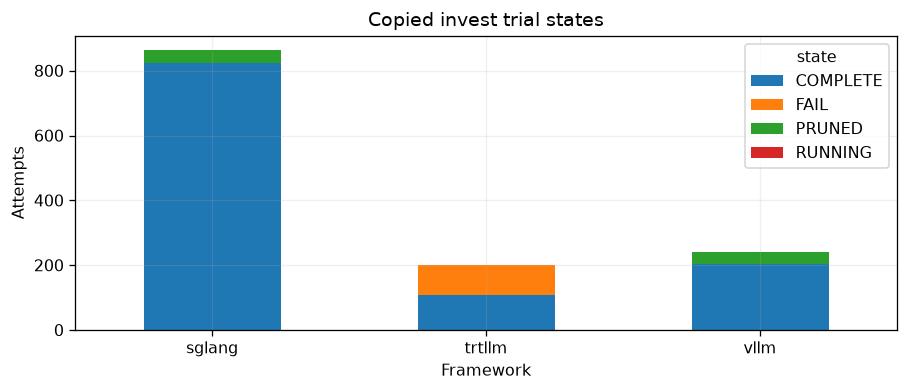

In [4]:
coverage = pd.crosstab([trials.framework, trials.campaign, trials.objective, trials.concurrency], trials.state)
display(coverage)
display(complete.groupby(["framework", "objective", "concurrency"]).agg(
    completed=("trial", "size"), studies=("study_key", "nunique"), feasible=("slo_feasible", lambda x: x.eq(True).sum())
))
environment_rows = []
for _, row in studies.drop_duplicates(["campaign"]).iterrows():
    env = row.contract.get("environment", {})
    environment_rows.append({"framework": row.framework, "campaign": row.campaign, "model": row.model,
                             **{k: env.get(k) for k in ["gpu_type", "framework_version", "cuda_version", "model_revision", "quality_verified"]}})
display(pd.DataFrame(environment_rows))
fig, ax = plt.subplots(figsize=(8, 3.5))
pd.crosstab(trials.framework, trials.state).plot.bar(stacked=True, ax=ax, rot=0)
ax.set(title="Copied invest trial states", ylabel="Attempts", xlabel="Framework")
plt.tight_layout(); plt.show()

## Two importance methods

1. **fANOVA** fits a random forest and estimates how much objective variation each parameter
   explains across the declared search space. Seed is fixed; these are first-order importances.
2. **PED-ANOVA** measures which parameters distinguish the better half of observed trials
   from the broader observed region (`evaluate_on_local=True`). The top-half choice gives at
   least five observations at the ten-trial minimum; top-10% would be too sparse here.

Both use Optuna's actual evaluators and the original SQLite parameter distributions. Original
objective directions are retained, so high throughput and low E2E latency select the correct
better trials. Each study is analyzed independently: seeds, samplers, objectives, campaign
revisions, and concurrency levels are never pooled into a synthetic optimization study.

Primary estimates use parameters present with an identical distribution in every eligible trial
of that study, omitting observed constants. Conditional and changing distributions are listed
below. Normalized importance sums to one **within each study/method**, not across engines.
Zero total signal is reported as undefined, rather than converted to artificial equal importance.
Small adaptive studies and pruned trials introduce selection bias; ranks are exploratory,
not causal effects or proof that a particular parameter value is optimal.

References: [Optuna fANOVA](https://optuna.readthedocs.io/en/v4.9.0/reference/generated/optuna.importance.FanovaImportanceEvaluator.html),
[Optuna PED-ANOVA](https://optuna.readthedocs.io/en/v4.9.0/reference/generated/optuna.importance.PedAnovaImportanceEvaluator.html).

In [5]:
importance_rows, importance_status, parameter_audit = [], [], []
analysis_studies = {}

def stable_varying_parameters(records):
    names = sorted(set().union(*(r["params"] for r in records)))
    included, audit = [], []
    for name in names:
        present = [r for r in records if name in r["params"]]
        dist_ids = {repr(r["distributions"][name]) for r in present}
        unique = {json.dumps(r["params"][name], sort_keys=True) for r in present}
        reason = ("conditional / missing" if len(present) < len(records) else
                  "changing distribution" if len(dist_ids) > 1 else
                  "observed constant" if len(unique) < 2 else "included")
        if reason == "included":
            included.append(name)
        audit.append({"parameter": name, "present": len(present), "eligible_trials": len(records),
                      "distinct_values": len(unique), "status": reason})
    return included, audit

def calculate_importance(records, meta, scope="common", branch="all"):
    included, audit = stable_varying_parameters(records)
    for a in audit:
        parameter_audit.append({**meta, "scope": scope, "branch": branch, **a})
    status = {**meta, "scope": scope, "branch": branch, "n_trials": len(records), "n_parameters": len(included)}
    if len(records) < MIN_TRIALS or not included or len({r["value"] for r in records}) < 2:
        importance_status.append({**status, "method": "both", "status": "skipped: sparse, constant target, or no varying common parameter"})
        return
    study = optuna.create_study(direction=meta["direction"])
    for r in records:
        study.add_trial(create_trial(value=r["value"], params={p: r["params"][p] for p in included},
                                     distributions={p: r["distributions"][p] for p in included}))
    if scope == "common":
        analysis_studies[meta["study_key"]] = study
    evaluators = {"fANOVA": FanovaImportanceEvaluator(n_trees=64, max_depth=32, seed=ANALYSIS_SEED),
                  "PED-ANOVA": PedAnovaImportanceEvaluator(target_quantile=PED_QUANTILE, evaluate_on_local=True)}
    for method, evaluator in evaluators.items():
        try:
            raw = get_param_importances(study, evaluator=evaluator, params=included, normalize=False)
            total = sum(raw.values())
            if not np.isfinite(total) or total <= 0:
                importance_status.append({**status, "method": method, "status": "undefined: zero total signal"})
                continue
            for name, value in raw.items():
                importance_rows.append({**status, "method": method, "parameter": name,
                                        "importance": value / total, "raw_importance": value})
            importance_status.append({**status, "method": method, "status": "ok"})
        except (ValueError, RuntimeError) as error:
            importance_status.append({**status, "method": method, "status": f"{type(error).__name__}: {error}"})

META = ["study_key", "framework", "campaign", "objective", "concurrency", "sampler", "sampler_seed", "direction"]
for key, frame in complete.groupby("study_key", sort=True):
    meta = {k: frame.iloc[0][k] for k in META}
    calculate_importance(frame.to_dict("records"), meta)

importance = pd.DataFrame(importance_rows)
status = pd.DataFrame(importance_status)
audit = pd.DataFrame(parameter_audit)
assert not importance.empty, "No eligible importance estimates; see status/audit"
display(status.groupby(["framework", "method", "status"]).size().rename("studies").to_frame())
display(audit[audit.status != "included"][["framework", "study_key", "parameter", "present", "eligible_trials", "status"]])

studies
framework method    status                                                                   
sglang    PED-ANOVA ok                                                                     43
          both      skipped: sparse, constant target, or no varying common parameter        1
          fANOVA    ok                                                                     43
trtllm    PED-ANOVA ok                                                                     10
          fANOVA    ok                                                                     10
vllm      PED-ANOVA ok                                                                     12
          fANOVA    ok                                                                     12

,framework,study_key,parameter,present,eligible_trials,status
5,sglang,phase1-sglang-v3-10195ab6a3fd087d/B-sglang-c128-throughput-tpe-median-s11,decode_capture_profile,14,20,conditional / missing
8,sglang,phase1-sglang-v3-10195ab6a3fd087d/B-sglang-c128-throughput-tpe-median-s11,kv_cache_precision,20,20,observed constant
15,sglang,phase1-sglang-v3-10195ab6a3fd087d/B-sglang-c128-throughput-tpe-median-s11,prefill_decode_interval_min_bs,14,20,conditional / missing
18,sglang,phase1-sglang-v3-10195ab6a3fd087d/B-sglang-c128-throughput-tpe-median-s11,triton_attention_num_kv_splits,3,20,conditional / missing
19,sglang,phase1-sglang-v3-10195ab6a3fd087d/B-sglang-c128-throughput-tpe-median-s11,weight_precision,20,20,observed constant
...,...,...,...,...,...,...
1274,vllm,phase1-vllm-v3-0ccdf535d50afbb5/B-vllm-c8-throughput-tpe-median-s29,weight_precision,18,18,observed constant
1280,vllm,phase1-vllm-v3-0ccdf535d50afbb5/B-vllm-c8-throughput-tpe_multivariate-median-s29,flash_attn_max_num_splits_for_cuda_graph,3,16,conditional / missing
1282,vllm,phase1-vllm-v3-0ccdf535d50afbb5/B-vllm-c8-throughput-tpe_multivariate-median-s29,graph_capture_profile,15,16,conditional / missing
1284,vllm,phase1-vllm-v3-0ccdf535d50afbb5/B-vllm-c8-throughput-tpe_multivariate-median-s29,kv_cache_precision,16,16,observed constant


## Importance plots: study-level estimates and agreement

Heatmaps show the equal-study mean of available normalized estimates within **one campaign
and objective**, with concurrency kept in columns. Gray cells mean no estimate, not zero.
Different samplers/seeds remain individual estimates; the tables expose their counts and
dispersion. Means are descriptive summaries, not a pooled model or a confidence interval.

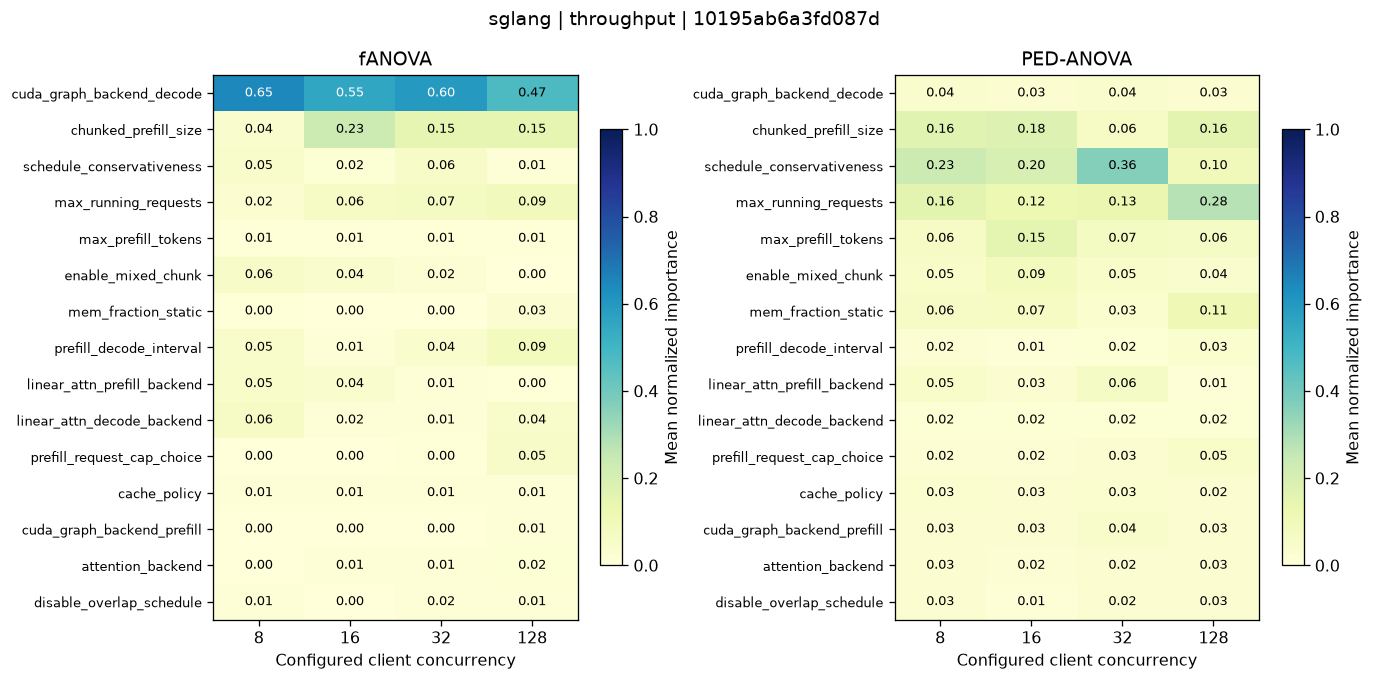

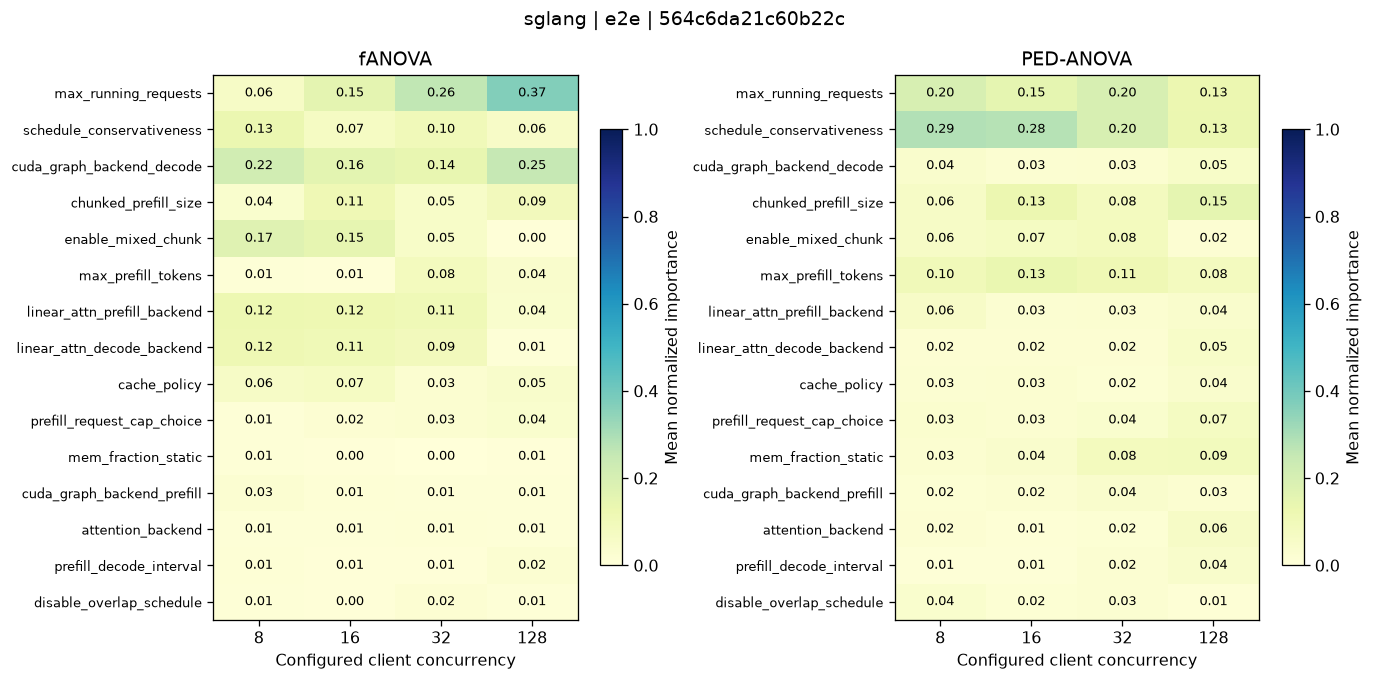

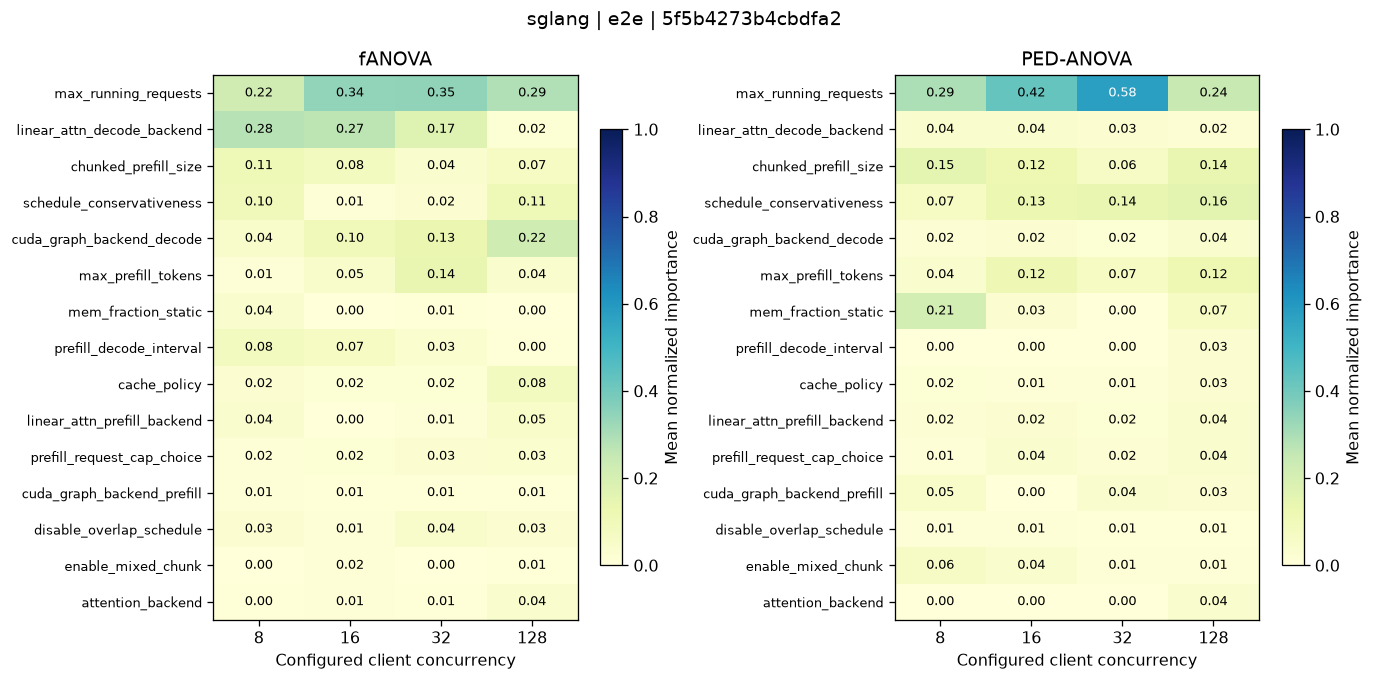

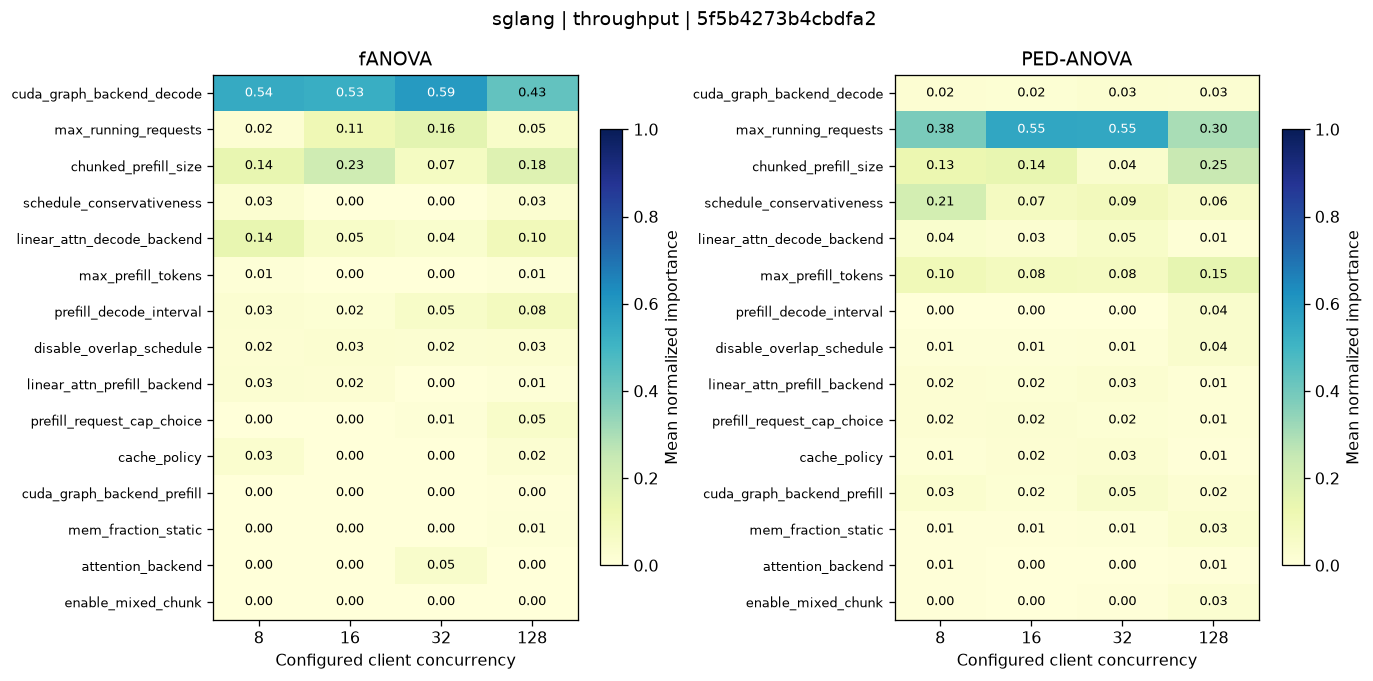

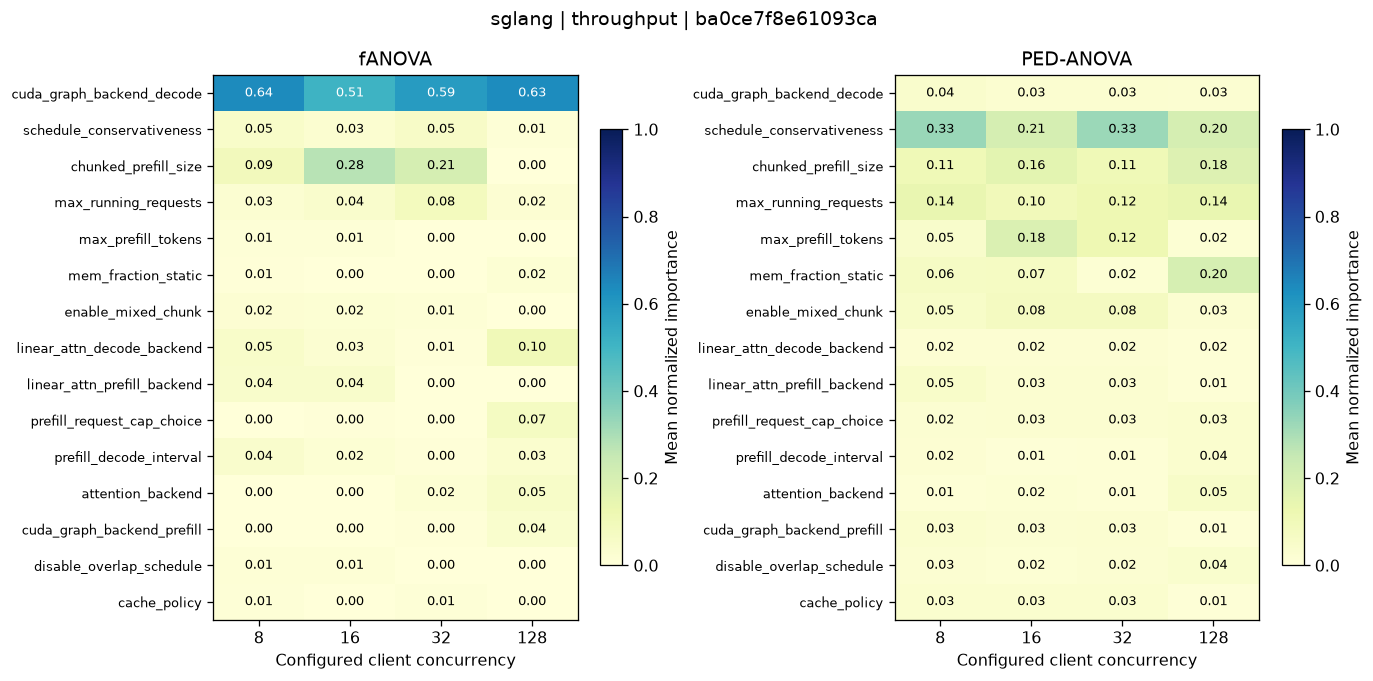

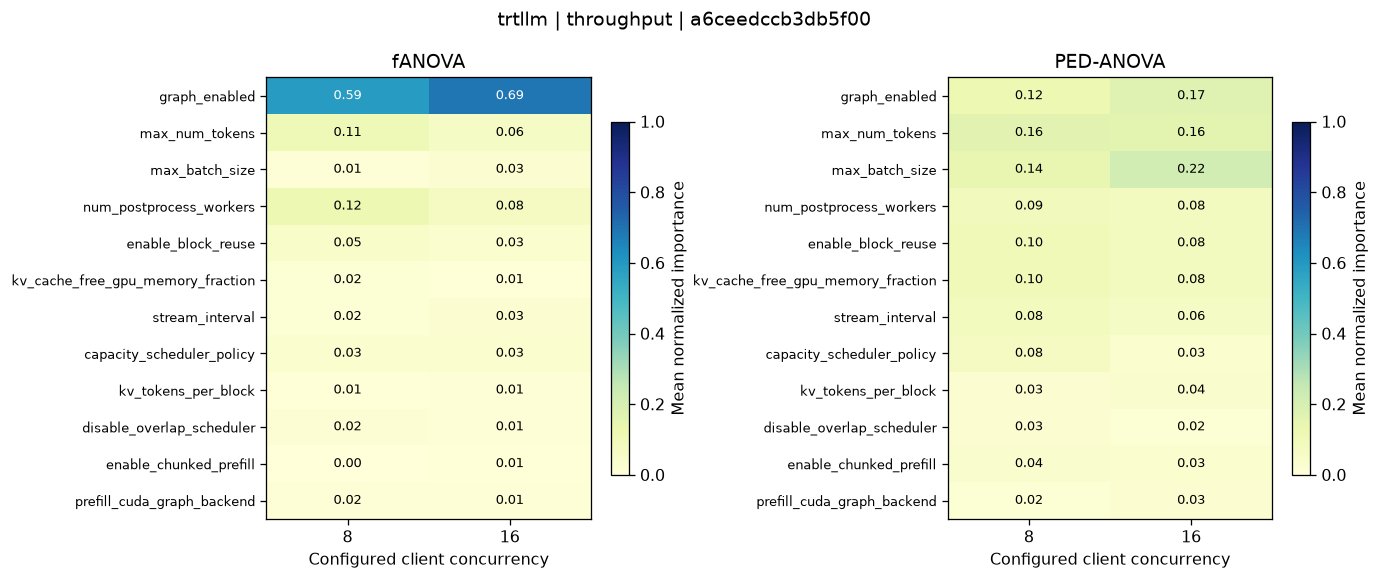

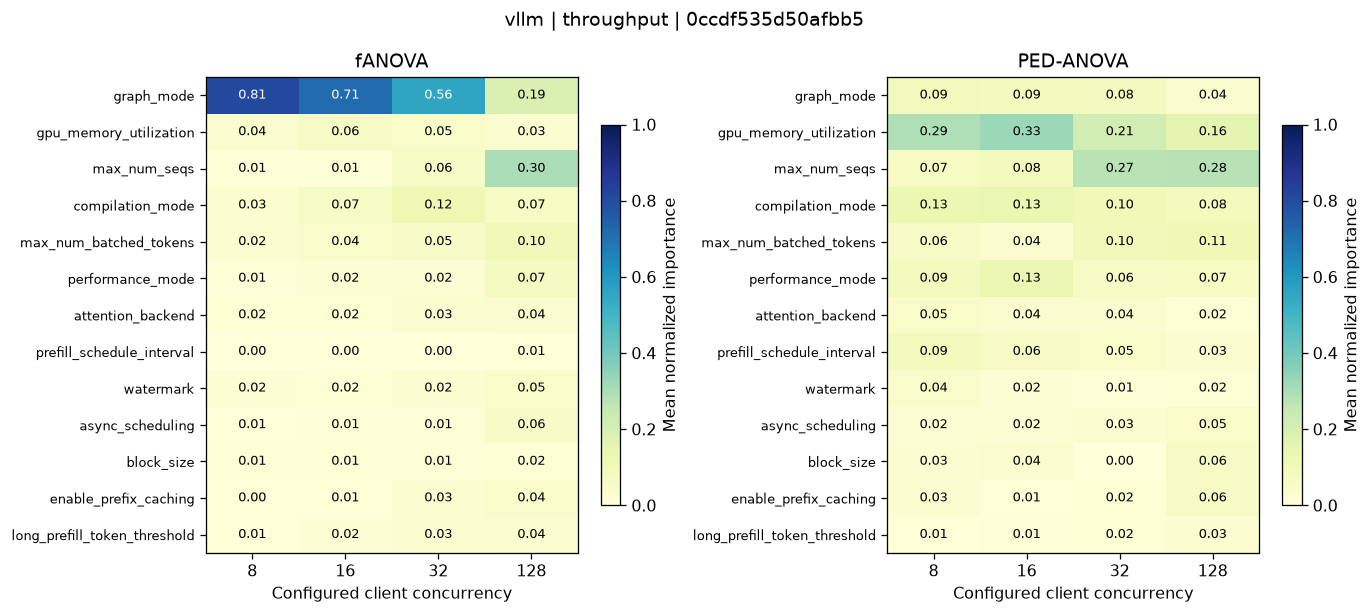

,framework,campaign,objective,concurrency,method,parameter,mean_importance,between_study_sd,n_studies
14,sglang,phase1-sglang-v3-10195ab6a3fd087d,throughput,8,PED-ANOVA,schedule_conservativeness,0.233054,0.221173,2
2,sglang,phase1-sglang-v3-10195ab6a3fd087d,throughput,8,PED-ANOVA,chunked_prefill_size,0.164936,0.129551,2
10,sglang,phase1-sglang-v3-10195ab6a3fd087d,throughput,8,PED-ANOVA,max_running_requests,0.156655,0.025667,2
18,sglang,phase1-sglang-v3-10195ab6a3fd087d,throughput,8,fANOVA,cuda_graph_backend_decode,0.645423,0.061094,2
22,sglang,phase1-sglang-v3-10195ab6a3fd087d,throughput,8,fANOVA,linear_attn_decode_backend,0.062163,0.077796,2
...,...,...,...,...,...,...,...,...,...
731,vllm,phase1-vllm-v3-0ccdf535d50afbb5,throughput,128,PED-ANOVA,gpu_memory_utilization,0.155426,0.098181,6
734,vllm,phase1-vllm-v3-0ccdf535d50afbb5,throughput,128,PED-ANOVA,max_num_batched_tokens,0.112121,0.085103,6
748,vllm,phase1-vllm-v3-0ccdf535d50afbb5,throughput,128,fANOVA,max_num_seqs,0.300261,0.320416,6
745,vllm,phase1-vllm-v3-0ccdf535d50afbb5,throughput,128,fANOVA,graph_mode,0.185497,0.259504,6


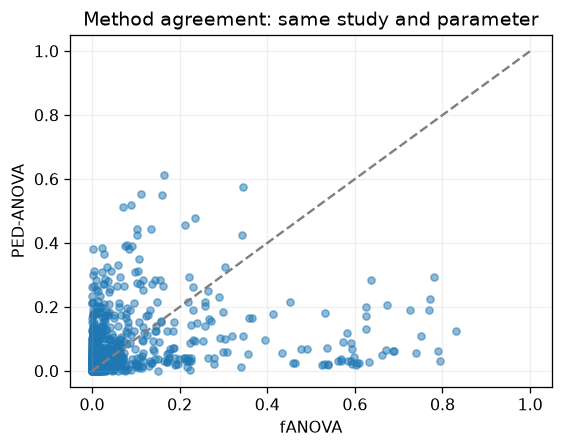

In [6]:
summary = importance.groupby(["framework", "campaign", "objective", "concurrency", "method", "parameter"], as_index=False).agg(
    mean_importance=("importance", "mean"), between_study_sd=("importance", "std"), n_studies=("study_key", "nunique")
)
for (fw, campaign, objective), frame in summary.groupby(["framework", "campaign", "objective"], sort=True):
    top = frame.groupby("parameter").mean_importance.mean().nlargest(18).index
    fig, axes = plt.subplots(1, 2, figsize=(12, max(3.5, 0.3 * len(top) + 1.5)), squeeze=False)
    for ax, method in zip(axes[0], ["fANOVA", "PED-ANOVA"]):
        matrix = frame[frame.method == method].pivot(index="parameter", columns="concurrency", values="mean_importance").reindex(top)
        cmap = plt.get_cmap("YlGnBu").copy(); cmap.set_bad("#e5e7eb")
        im = ax.imshow(matrix.to_numpy(), aspect="auto", cmap=cmap, vmin=0, vmax=1)
        ax.set_xticks(range(len(matrix.columns)), matrix.columns)
        ax.set_yticks(range(len(matrix.index)), matrix.index, fontsize=8)
        ax.set(title=method, xlabel="Configured client concurrency")
        ax.grid(False)
        for i in range(len(matrix.index)):
            for j in range(len(matrix.columns)):
                value = matrix.iloc[i, j]
                if pd.notna(value): ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=8,
                                            color="white" if value > 0.5 else "black")
        fig.colorbar(im, ax=ax, shrink=0.8, label="Mean normalized importance")
    fig.suptitle(f"{fw} | {objective} | {campaign.rsplit('-', 1)[-1]}")
    fig.tight_layout(); plt.show()

top_table = summary.sort_values("mean_importance", ascending=False).groupby(
    ["framework", "campaign", "objective", "concurrency", "method"], sort=False).head(3)
display(top_table.sort_values(["framework", "campaign", "objective", "concurrency", "method", "mean_importance"],
                             ascending=[True, True, True, True, True, False]))
agreement = importance.pivot(index=["study_key", "parameter"], columns="method", values="importance").dropna()
fig, ax = plt.subplots(figsize=(5, 4))
ax.scatter(agreement["fANOVA"], agreement["PED-ANOVA"], alpha=0.5, s=20)
ax.plot([0, 1], [0, 1], "--", color="gray")
ax.set(xlabel="fANOVA", ylabel="PED-ANOVA", title="Method agreement: same study and parameter")
plt.tight_layout(); plt.show()

## Inspect an individual study

Change `SELECTED_STUDY` to any key in `analysis_studies`. Error bars below show variation
across three random-forest seeds only; they are not confidence intervals or sampling uncertainty.
PED-ANOVA is deterministic for a fixed study. A stable forest rank can still be unreliable
when the search samples too few configurations.

Selected: phase1-sglang-v3-10195ab6a3fd087d/B-sglang-c128-throughput-tpe-median-s11


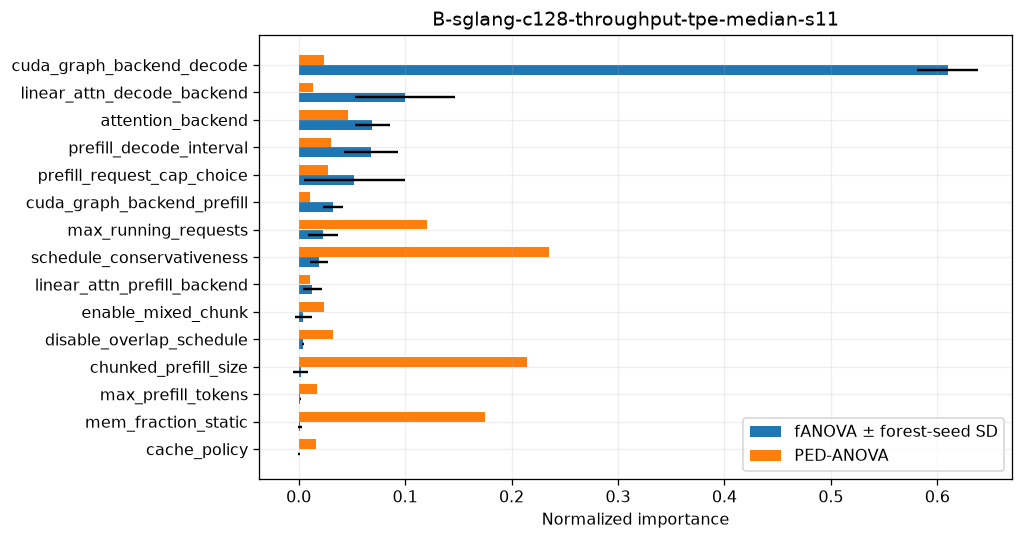

,trial,value,slo_feasible,params
133,13,7530.451793,False,"{'max_running_requests': 112, 'chunked_prefill_size': 19456, 'mem_fraction_static': 0.75, 'cache_policy': ..."
131,11,7357.035028,False,"{'max_running_requests': 128, 'chunked_prefill_size': 20224, 'mem_fraction_static': 0.7, 'cache_policy': '..."
136,16,7344.347247,False,"{'max_running_requests': 112, 'chunked_prefill_size': 17152, 'mem_fraction_static': 0.7, 'cache_policy': '..."
134,14,7336.163629,False,"{'max_running_requests': 112, 'chunked_prefill_size': 20992, 'mem_fraction_static': 0.7, 'cache_policy': '..."
138,18,7308.777886,False,"{'max_running_requests': 128, 'chunked_prefill_size': 17152, 'mem_fraction_static': 0.7, 'cache_policy': '..."
135,15,7176.017632,False,"{'max_running_requests': 120, 'chunked_prefill_size': 20480, 'mem_fraction_static': 0.75, 'cache_policy': ..."
137,17,7120.415248,False,"{'max_running_requests': 88, 'chunked_prefill_size': 25088, 'mem_fraction_static': 0.75, 'cache_policy': '..."
139,19,7046.276456,False,"{'max_running_requests': 80, 'chunked_prefill_size': 5120, 'mem_fraction_static': 0.75, 'cache_policy': 'o..."
132,12,6283.633447,False,"{'max_running_requests': 104, 'chunked_prefill_size': 20480, 'mem_fraction_static': 0.75, 'cache_policy': ..."
122,2,5234.177577,False,"{'max_running_requests': 96, 'chunked_prefill_size': 30720, 'mem_fraction_static': 0.75, 'cache_policy': '..."


In [7]:
SELECTED_STUDY = sorted(analysis_studies)[0]
print("Selected:", SELECTED_STUDY)
detail = importance[importance.study_key == SELECTED_STUDY].pivot(index="parameter", columns="method", values="importance")
detail = detail.sort_values("fANOVA", ascending=True)
forest_repeats = []
selected = analysis_studies[SELECTED_STUDY]
for seed in [11, 29, 47]:
    forest_repeats.append(get_param_importances(selected, evaluator=FanovaImportanceEvaluator(n_trees=64, max_depth=32, seed=seed)))
forest_sd = pd.DataFrame(forest_repeats).std().reindex(detail.index)
fig, ax = plt.subplots(figsize=(9, max(4, len(detail) * 0.32)))
y = np.arange(len(detail))
ax.barh(y - 0.18, detail["fANOVA"], height=0.35, xerr=forest_sd, label="fANOVA ± forest-seed SD")
ax.barh(y + 0.18, detail["PED-ANOVA"], height=0.35, label="PED-ANOVA")
ax.set_yticks(y, detail.index)
ax.set(xlabel="Normalized importance", title=SELECTED_STUDY.split("/")[-1])
ax.legend(); plt.tight_layout(); plt.show()
display(complete.loc[complete.study_key == SELECTED_STUDY, ["trial", "value", "slo_feasible", "params"]].sort_values("value", ascending=selected.direction.name == "MINIMIZE"))

## Conditional branches

Common-parameter estimates omit optional parameters that appear only in some trials.
For each study, this cell also groups trials by the exact parameter-presence pattern and
estimates importance inside branches with at least ten completed measured trials. Branch
estimates answer a different, conditional question and must not be averaged with the primary
results. Branch-specific constants (including branch selectors) cannot be ranked inside a
branch. Sparse branches remain explicitly unestimated.

In [8]:
branch_counts = []
start_importance, start_status = len(importance_rows), len(importance_status)
for key, frame in complete.groupby("study_key", sort=True):
    groups = defaultdict(list)
    for record in frame.to_dict("records"):
        groups[tuple(sorted(record["params"]))].append(record)
    if len(groups) <= 1:
        continue
    meta = {k: frame.iloc[0][k] for k in META}
    for i, (names, records) in enumerate(sorted(groups.items()), 1):
        branch = f"presence-pattern-{i}"
        branch_counts.append({"study_key": key, "branch": branch, "n_trials": len(records), "parameters": ", ".join(names)})
        calculate_importance(records, meta, scope="conditional", branch=branch)
branch_importance = pd.DataFrame(importance_rows[start_importance:])
display(pd.DataFrame(branch_counts))
display(pd.DataFrame(importance_status[start_status:]))
if not branch_importance.empty:
    branch_top = branch_importance.sort_values("importance", ascending=False).groupby(["study_key", "branch", "method"]).head(3)
    display(branch_top[["study_key", "branch", "n_trials", "method", "parameter", "importance"]])
else:
    print("No conditional branch has enough varying completed measured data for importance.")

,study_key,branch,n_trials,parameters
0,phase1-sglang-v3-10195ab6a3fd087d/B-sglang-c128-throughput-tpe-median-s11,presence-pattern-1,2,"attention_backend, cache_policy, chunked_prefill_size, cuda_graph_backend_decode, cuda_graph_backend_prefi..."
1,phase1-sglang-v3-10195ab6a3fd087d/B-sglang-c128-throughput-tpe-median-s11,presence-pattern-2,11,"attention_backend, cache_policy, chunked_prefill_size, cuda_graph_backend_decode, cuda_graph_backend_prefi..."
2,phase1-sglang-v3-10195ab6a3fd087d/B-sglang-c128-throughput-tpe-median-s11,presence-pattern-3,1,"attention_backend, cache_policy, chunked_prefill_size, cuda_graph_backend_decode, cuda_graph_backend_prefi..."
3,phase1-sglang-v3-10195ab6a3fd087d/B-sglang-c128-throughput-tpe-median-s11,presence-pattern-4,1,"attention_backend, cache_policy, chunked_prefill_size, cuda_graph_backend_decode, cuda_graph_backend_prefi..."
4,phase1-sglang-v3-10195ab6a3fd087d/B-sglang-c128-throughput-tpe-median-s11,presence-pattern-5,1,"attention_backend, cache_policy, chunked_prefill_size, cuda_graph_backend_decode, cuda_graph_backend_prefi..."
...,...,...,...,...
355,phase1-vllm-v3-0ccdf535d50afbb5/B-vllm-c8-throughput-tpe-median-s29,presence-pattern-2,8,"async_scheduling, attention_backend, block_size, compilation_mode, enable_prefix_caching, gpu_memory_utili..."
356,phase1-vllm-v3-0ccdf535d50afbb5/B-vllm-c8-throughput-tpe-median-s29,presence-pattern-3,1,"async_scheduling, attention_backend, block_size, compilation_mode, enable_prefix_caching, gpu_memory_utili..."
357,phase1-vllm-v3-0ccdf535d50afbb5/B-vllm-c8-throughput-tpe_multivariate-median-s29,presence-pattern-1,3,"async_scheduling, attention_backend, block_size, compilation_mode, enable_prefix_caching, flash_attn_max_n..."
358,phase1-vllm-v3-0ccdf535d50afbb5/B-vllm-c8-throughput-tpe_multivariate-median-s29,presence-pattern-2,12,"async_scheduling, attention_backend, block_size, compilation_mode, enable_prefix_caching, gpu_memory_utili..."


,study_key,framework,campaign,objective,concurrency,sampler,sampler_seed,direction,scope,branch,n_trials,n_parameters,method,status
0,phase1-sglang-v3-10195ab6a3fd087d/B-sglang-c128-throughput-tpe-median-s11,sglang,phase1-sglang-v3-10195ab6a3fd087d,throughput,128,tpe,11,maximize,conditional,presence-pattern-1,2,7,both,"skipped: sparse, constant target, or no varying common parameter"
1,phase1-sglang-v3-10195ab6a3fd087d/B-sglang-c128-throughput-tpe-median-s11,sglang,phase1-sglang-v3-10195ab6a3fd087d,throughput,128,tpe,11,maximize,conditional,presence-pattern-2,11,14,fANOVA,ok
2,phase1-sglang-v3-10195ab6a3fd087d/B-sglang-c128-throughput-tpe-median-s11,sglang,phase1-sglang-v3-10195ab6a3fd087d,throughput,128,tpe,11,maximize,conditional,presence-pattern-2,11,14,PED-ANOVA,ok
3,phase1-sglang-v3-10195ab6a3fd087d/B-sglang-c128-throughput-tpe-median-s11,sglang,phase1-sglang-v3-10195ab6a3fd087d,throughput,128,tpe,11,maximize,conditional,presence-pattern-3,1,0,both,"skipped: sparse, constant target, or no varying common parameter"
4,phase1-sglang-v3-10195ab6a3fd087d/B-sglang-c128-throughput-tpe-median-s11,sglang,phase1-sglang-v3-10195ab6a3fd087d,throughput,128,tpe,11,maximize,conditional,presence-pattern-4,1,0,both,"skipped: sparse, constant target, or no varying common parameter"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
370,phase1-vllm-v3-0ccdf535d50afbb5/B-vllm-c8-throughput-tpe-median-s29,vllm,phase1-vllm-v3-0ccdf535d50afbb5,throughput,8,tpe,29,maximize,conditional,presence-pattern-3,1,0,both,"skipped: sparse, constant target, or no varying common parameter"
371,phase1-vllm-v3-0ccdf535d50afbb5/B-vllm-c8-throughput-tpe_multivariate-median-s29,vllm,phase1-vllm-v3-0ccdf535d50afbb5,throughput,8,tpe_multivariate,29,maximize,conditional,presence-pattern-1,3,8,both,"skipped: sparse, constant target, or no varying common parameter"
372,phase1-vllm-v3-0ccdf535d50afbb5/B-vllm-c8-throughput-tpe_multivariate-median-s29,vllm,phase1-vllm-v3-0ccdf535d50afbb5,throughput,8,tpe_multivariate,29,maximize,conditional,presence-pattern-2,12,14,fANOVA,ok
373,phase1-vllm-v3-0ccdf535d50afbb5/B-vllm-c8-throughput-tpe_multivariate-median-s29,vllm,phase1-vllm-v3-0ccdf535d50afbb5,throughput,8,tpe_multivariate,29,maximize,conditional,presence-pattern-2,12,14,PED-ANOVA,ok


,study_key,branch,n_trials,method,parameter,importance
68,phase1-sglang-v3-5f5b4273b4cbdfa2/B-sglang-c128-throughput-gp-nop-s29,presence-pattern-2,11,PED-ANOVA,max_running_requests,0.590229
314,phase1-vllm-v3-0ccdf535d50afbb5/B-vllm-c128-throughput-tpe_multivariate-median-s47,presence-pattern-2,11,PED-ANOVA,max_num_batched_tokens,0.540182
272,phase1-vllm-v3-0ccdf535d50afbb5/B-vllm-c128-throughput-tpe_multivariate-median-s29,presence-pattern-2,13,fANOVA,graph_mode,0.493168
14,phase1-sglang-v3-10195ab6a3fd087d/B-sglang-c128-throughput-tpe-median-s11,presence-pattern-2,11,PED-ANOVA,chunked_prefill_size,0.461232
28,phase1-sglang-v3-5f5b4273b4cbdfa2/B-sglang-c128-throughput-gp-nop-s11,presence-pattern-1,13,fANOVA,disable_overlap_schedule,0.459958
384,phase1-vllm-v3-0ccdf535d50afbb5/B-vllm-c8-throughput-tpe_multivariate-median-s29,presence-pattern-2,12,fANOVA,graph_mode,0.434925
370,phase1-vllm-v3-0ccdf535d50afbb5/B-vllm-c32-throughput-tpe_multivariate-median-s29,presence-pattern-2,12,PED-ANOVA,max_num_seqs,0.428982
230,phase1-vllm-v3-0ccdf535d50afbb5/B-vllm-c128-throughput-tpe-median-s47,presence-pattern-2,11,PED-ANOVA,max_num_seqs,0.425742
216,phase1-vllm-v3-0ccdf535d50afbb5/B-vllm-c128-throughput-tpe-median-s47,presence-pattern-2,11,fANOVA,async_scheduling,0.420762
286,phase1-vllm-v3-0ccdf535d50afbb5/B-vllm-c128-throughput-tpe_multivariate-median-s29,presence-pattern-2,13,PED-ANOVA,max_num_seqs,0.406811


## Benchmark performance and best observed configurations

Throughput is output tokens/second; E2E and TTFT are per-trial p95 request latencies in ms.
Plots show individual completed measured trials, not validation repeats. Best configurations
are selected within each study using its original direction; `slo_feasible` stays visible.
Different search objectives, samplers, and local campaign revisions are not a controlled
head-to-head engine benchmark.

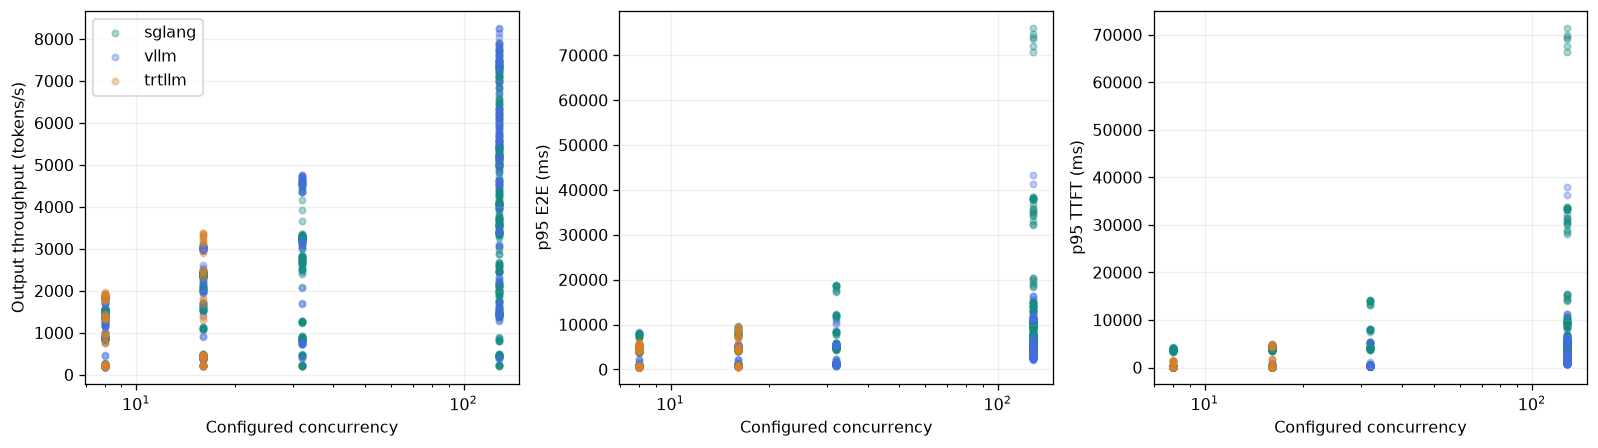

,study_key,objective,concurrency,value,slo_feasible,params
133,phase1-sglang-v3-10195ab6a3fd087d/B-sglang-c128-throughput-tpe-median-s11,throughput,128,7530.451793,False,"{'max_running_requests': 112, 'chunked_prefill_size': 19456, 'mem_fraction_static': 0.75, 'cache_policy': ..."
155,phase1-sglang-v3-10195ab6a3fd087d/B-sglang-c128-throughput-tpe-median-s29,throughput,128,5446.127343,False,"{'max_running_requests': 112, 'chunked_prefill_size': 11008, 'mem_fraction_static': 0.75, 'cache_policy': ..."
179,phase1-sglang-v3-10195ab6a3fd087d/B-sglang-c128-throughput-tpe-median-s47,throughput,128,6298.339279,False,"{'max_running_requests': 104, 'chunked_prefill_size': 13824, 'mem_fraction_static': 0.7, 'cache_policy': '..."
198,phase1-sglang-v3-10195ab6a3fd087d/B-sglang-c128-throughput-tpe_multivariate-median-s11,throughput,128,7731.037947,False,"{'max_running_requests': 120, 'chunked_prefill_size': 26368, 'mem_fraction_static': 0.75, 'cache_policy': ..."
216,phase1-sglang-v3-10195ab6a3fd087d/B-sglang-c128-throughput-tpe_multivariate-median-s29,throughput,128,6440.779734,False,"{'max_running_requests': 120, 'chunked_prefill_size': 10496, 'mem_fraction_static': 0.7, 'cache_policy': '..."
235,phase1-sglang-v3-10195ab6a3fd087d/B-sglang-c128-throughput-tpe_multivariate-median-s47,throughput,128,4540.104402,False,"{'max_running_requests': 128, 'chunked_prefill_size': 5888, 'mem_fraction_static': 0.75, 'cache_policy': '..."
53,phase1-sglang-v3-10195ab6a3fd087d/B-sglang-c16-throughput-tpe-median-s29,throughput,16,2373.416621,True,"{'max_running_requests': 96, 'chunked_prefill_size': 10496, 'mem_fraction_static': 0.85, 'cache_policy': '..."
74,phase1-sglang-v3-10195ab6a3fd087d/B-sglang-c16-throughput-tpe_multivariate-median-s29,throughput,16,3052.611044,True,"{'max_running_requests': 120, 'chunked_prefill_size': 4608, 'mem_fraction_static': 0.75, 'cache_policy': '..."
94,phase1-sglang-v3-10195ab6a3fd087d/B-sglang-c32-throughput-tpe-median-s29,throughput,32,3242.538207,False,"{'max_running_requests': 72, 'chunked_prefill_size': 11776, 'mem_fraction_static': 0.75, 'cache_policy': '..."
113,phase1-sglang-v3-10195ab6a3fd087d/B-sglang-c32-throughput-tpe_multivariate-median-s29,throughput,32,4477.794268,False,"{'max_running_requests': 72, 'chunked_prefill_size': 20992, 'mem_fraction_static': 0.7999999999999999, 'ca..."


In [9]:
for metric in ["output_throughput", "p95_e2e_latency_ms", "p95_ttft_ms", "request_throughput", "wall_seconds", "gpu_seconds"]:
    complete[metric] = complete.measurement.map(lambda m: m.get(metric, np.nan))
complete["request_throughput"] = [m.get("request_throughput", a.get("request_throughput", np.nan)) for m, a in zip(complete.measurement, complete["attrs"])]
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, metric, label in zip(axes, ["output_throughput", "p95_e2e_latency_ms", "p95_ttft_ms"], ["Output throughput (tokens/s)", "p95 E2E (ms)", "p95 TTFT (ms)"]):
    for fw in FRAMEWORKS:
        data = complete[complete.framework == fw]
        ax.scatter(data.concurrency, data[metric], color=COLORS[fw], alpha=0.35, s=16, label=fw)
    ax.set(xscale="log", xlabel="Configured concurrency", ylabel=label)
axes[0].legend(); fig.tight_layout(); plt.show()
best_indices = []
for _, frame in complete.groupby("study_key"):
    best_indices.append(frame.value.idxmax() if frame.direction.iloc[0] == "maximize" else frame.value.idxmin())
best = complete.loc[best_indices, ["study_key", "objective", "concurrency", "value", "slo_feasible", "params"]]
display(best)

## Telemetry extraction and missing-data audit

Server gauges are sampled during each measured benchmark window. Stored time-weighted
averages describe the covered part of that window; `coverage` reports the represented fraction.
They are not GPU kernel occupancy. Client in-flight counts include transport time. Cache ratios
can include retained state and have engine-specific meanings.

Only explicitly available finite metrics are plotted. Missing gauges stay NaN, including
unavailable GPU utilization. Coverage summaries include missing observations in their
denominator; no missing telemetry is replaced with a measured zero. The coverage threshold
for descriptive server plots is 80%. No raw time series is reconstructed from summaries.

,framework,metric,attempted,available,median_coverage,median_samples,available_fraction
0,sglang,cache_pool_bottleneck,823,823,0.998961,45.0,1.0
1,sglang,client_requests_in_flight,823,823,NaN,NaN,1.0
2,sglang,gpu_utilization,823,0,0.000000,0.0,0.0
3,sglang,kv_cache_utilization,823,823,0.998961,45.0,1.0
4,sglang,queued_requests,823,823,0.998961,45.0,1.0
5,sglang,recurrent_state_utilization,823,823,0.998961,45.0,1.0
6,sglang,running_requests,823,823,0.998961,45.0,1.0
7,trtllm,cache_pool_bottleneck,108,0,NaN,NaN,0.0
8,trtllm,client_requests_in_flight,108,108,NaN,NaN,1.0
9,trtllm,gpu_utilization,108,0,0.000000,0.0,0.0


trials
framework metric                      reason                                                        
sglang    gpu_utilization             gpu_index not configured; no device inferred               823
trtllm    cache_pool_bottleneck       not recorded / not exposed                                 108
          gpu_utilization             gpu_index not configured; no device inferred               108
          kv_cache_utilization        metric not exposed                                          94
                                      metric not exposed; metrics scrape failed: ReadTimeout      14
          queued_requests             metric not exposed                                          94
                                      metric not exposed; metrics scrape failed: ReadTimeout      14
          recurrent_state_utilization not recorded / not exposed                                 108
          running_requests            metric not exposed                                          94
                                      metric not exposed; metrics scrape failed: ReadTimeout      14
vllm      cache_pool_bottleneck       not recorded / not exposed                                 204
          gpu_utilization             gpu_index not configured; no device inferred               204
          recurrent_state_utilization not recorded / not exposed                                 204

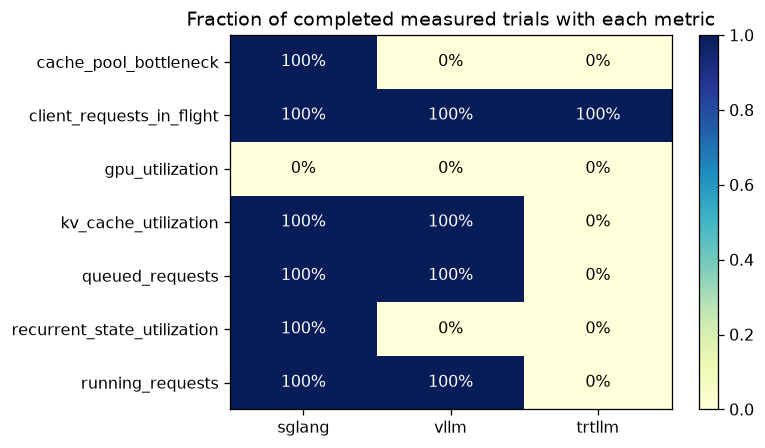

In [10]:
TELEMETRY_MIN_COVERAGE = 0.8
telemetry_rows, timing_rows = [], []
for _, r in complete.iterrows():
    base = {k: r[k] for k in ["study_key", "framework", "campaign", "objective", "concurrency", "trial", "value", "output_throughput", "p95_e2e_latency_ms"]}
    telemetry = r.telemetry
    metrics = telemetry.get("metrics", {})
    for name in ["running_requests", "queued_requests", "kv_cache_utilization", "cache_pool_bottleneck", "recurrent_state_utilization", "gpu_utilization", "client_requests_in_flight"]:
        metric = telemetry.get(name, {}) if name == "client_requests_in_flight" else metrics.get(name, {})
        value = metric.get("time_weighted_avg")
        available = (metric.get("available", value is not None) is True and value is not None and np.isfinite(value))
        peak = metric.get("peak")
        telemetry_rows.append({**base, "metric": name, "available": available,
                               "average": value if available else np.nan,
                               "peak": peak if available and peak is not None and np.isfinite(peak) else np.nan,
                               "coverage": metric.get("coverage", np.nan), "unit": metric.get("unit"),
                               "samples": metric.get("sample_count", np.nan),
                               "reason": metric.get("reason") or ("" if available else "not recorded / not exposed")})
    for name, value in r.execution.get("timings_s", {}).items():
        if isinstance(value, (int, float)) and np.isfinite(value):
            timing_rows.append({**base, "phase": name, "seconds": value})
telemetry = pd.DataFrame(telemetry_rows)
timings = pd.DataFrame(timing_rows)
telemetry_audit = telemetry.groupby(["framework", "metric"], as_index=False).agg(
    attempted=("available", "size"), available=("available", "sum"), median_coverage=("coverage", "median"), median_samples=("samples", "median")
)
telemetry_audit["available_fraction"] = telemetry_audit.available / telemetry_audit.attempted
display(telemetry_audit)
display(telemetry[~telemetry.available].groupby(["framework", "metric", "reason"]).size().rename("trials").to_frame())
matrix = telemetry_audit.pivot(index="metric", columns="framework", values="available_fraction").reindex(columns=FRAMEWORKS)
fig, ax = plt.subplots(figsize=(7, 4))
im = ax.imshow(matrix, aspect="auto", vmin=0, vmax=1, cmap="YlGnBu")
ax.set_xticks(range(len(matrix.columns)), matrix.columns)
ax.set_yticks(range(len(matrix.index)), matrix.index)
for i in range(len(matrix.index)):
    for j in range(len(matrix.columns)):
        value = matrix.iloc[i, j]
        ax.text(j, i, f"{value:.0%}", ha="center", va="center", color="white" if value > 0.5 else "black")
ax.set_title("Fraction of completed measured trials with each metric")
ax.grid(False); fig.colorbar(im, ax=ax); fig.tight_layout(); plt.show()

## Request pressure, queueing, and cache utilization

Each panel summarizes per-trial measured-window averages and peaks using the median across
available trials at the same configured concurrency. All recorded search objectives are shown
together descriptively here. No cross-engine cache capacity equivalence is implied.

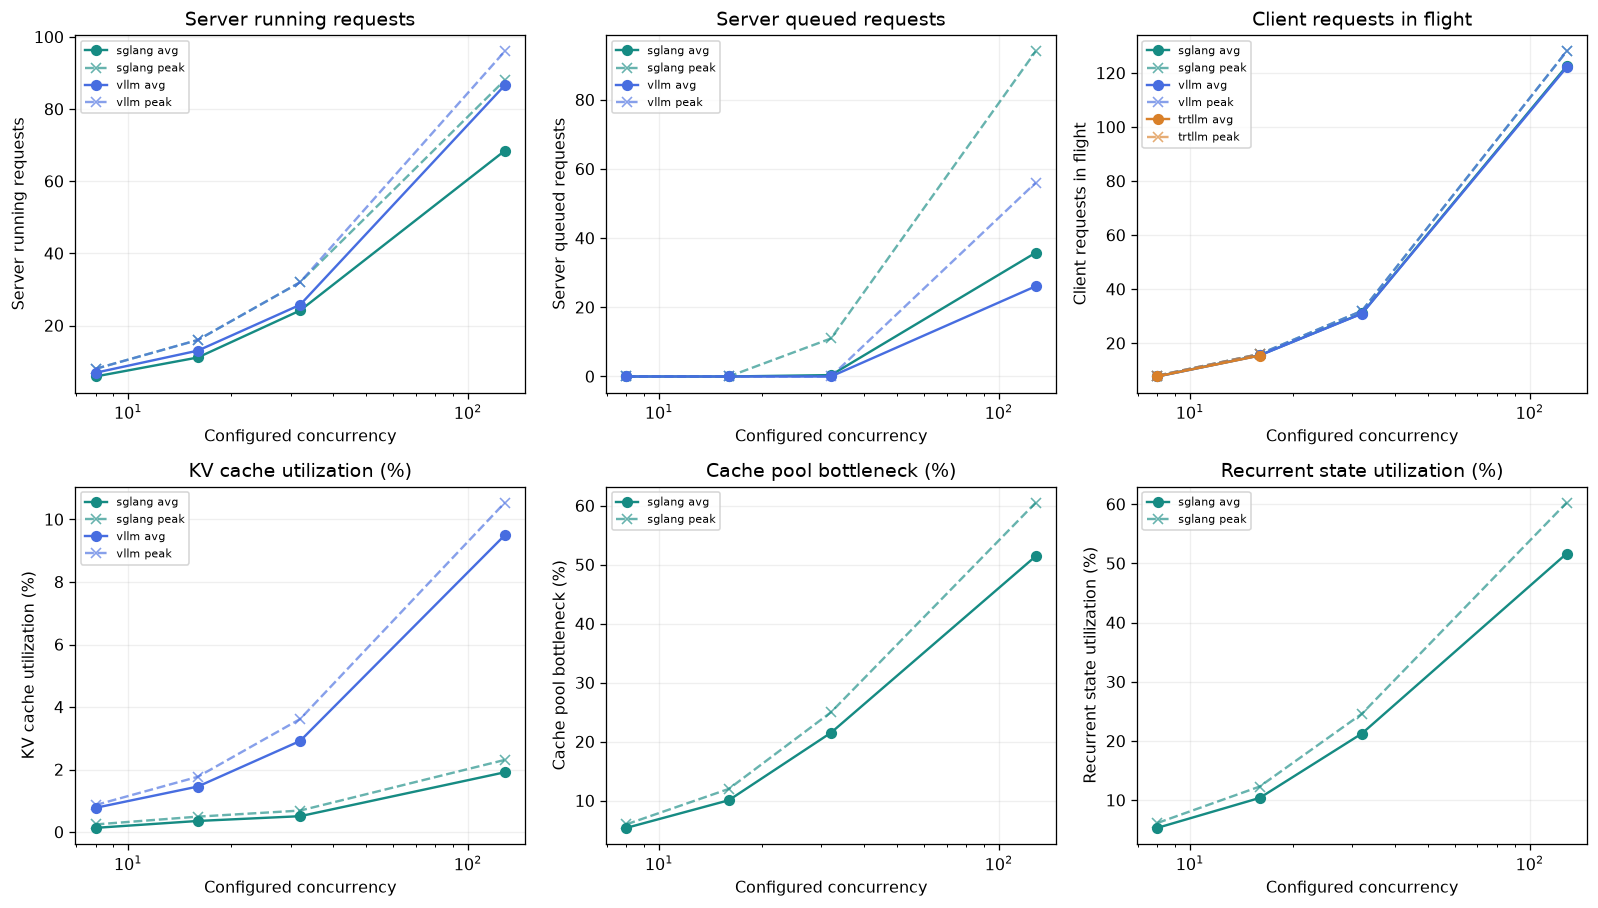

,framework,objective,concurrency,metric,unit,trials,median_average,median_peak,median_coverage
0,sglang,e2e,8,cache_pool_bottleneck,fraction,54,0.053158,0.060000,0.997427
1,sglang,e2e,8,client_requests_in_flight,requests,54,7.747356,8.000000,NaN
2,sglang,e2e,8,kv_cache_utilization,fraction,54,0.001835,0.002361,0.997427
3,sglang,e2e,8,queued_requests,requests,54,0.000000,0.000000,0.997427
4,sglang,e2e,8,recurrent_state_utilization,fraction,54,0.051224,0.061538,0.997427
5,sglang,e2e,8,running_requests,requests,54,5.892569,8.000000,0.997427
6,sglang,e2e,16,cache_pool_bottleneck,fraction,58,0.100736,0.120000,0.998046
7,sglang,e2e,16,client_requests_in_flight,requests,58,15.587502,16.000000,NaN
8,sglang,e2e,16,kv_cache_utilization,fraction,58,0.003545,0.004996,0.998046
9,sglang,e2e,16,queued_requests,requests,58,0.000000,0.000000,0.998046


In [11]:
usable = telemetry[telemetry.available & ((telemetry.coverage >= TELEMETRY_MIN_COVERAGE) | telemetry.metric.eq("client_requests_in_flight"))].copy()
metric_labels = {
    "running_requests": "Server running requests", "queued_requests": "Server queued requests",
    "client_requests_in_flight": "Client requests in flight", "kv_cache_utilization": "KV cache utilization (%)",
    "cache_pool_bottleneck": "Cache pool bottleneck (%)", "recurrent_state_utilization": "Recurrent state utilization (%)",
}
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, (metric, label) in zip(axes.flat, metric_labels.items()):
    data = usable[usable.metric == metric].copy()
    factor = 100 if data.unit.eq("fraction").any() else 1
    for fw in FRAMEWORKS:
        grouped = data[data.framework == fw].groupby("concurrency")[["average", "peak"]].median()
        if grouped.empty: continue
        ax.plot(grouped.index, grouped.average * factor, "o-", color=COLORS[fw], label=f"{fw} avg")
        ax.plot(grouped.index, grouped.peak * factor, "x--", color=COLORS[fw], alpha=0.65, label=f"{fw} peak")
    if data.empty:
        ax.text(0.5, 0.5, "No available observations", transform=ax.transAxes, ha="center")
    else:
        ax.legend(fontsize=7)
    ax.set(xscale="log", xlabel="Configured concurrency", ylabel=label, title=label)
fig.tight_layout(); plt.show()
telemetry_results = usable.groupby(["framework", "objective", "concurrency", "metric", "unit"], as_index=False).agg(
    trials=("average", "size"), median_average=("average", "median"), median_peak=("peak", "median"), median_coverage=("coverage", "median")
)
display(telemetry_results)

## Telemetry versus latency: within-concurrency associations

Separate concurrency columns avoid interpreting workload size as a tuning effect.
Points are individual trials; correlations/visual trends are observational and can reflect
other configuration changes. Only available gauges with at least 80% measured-window coverage
are included. Empty panels indicate absent data.

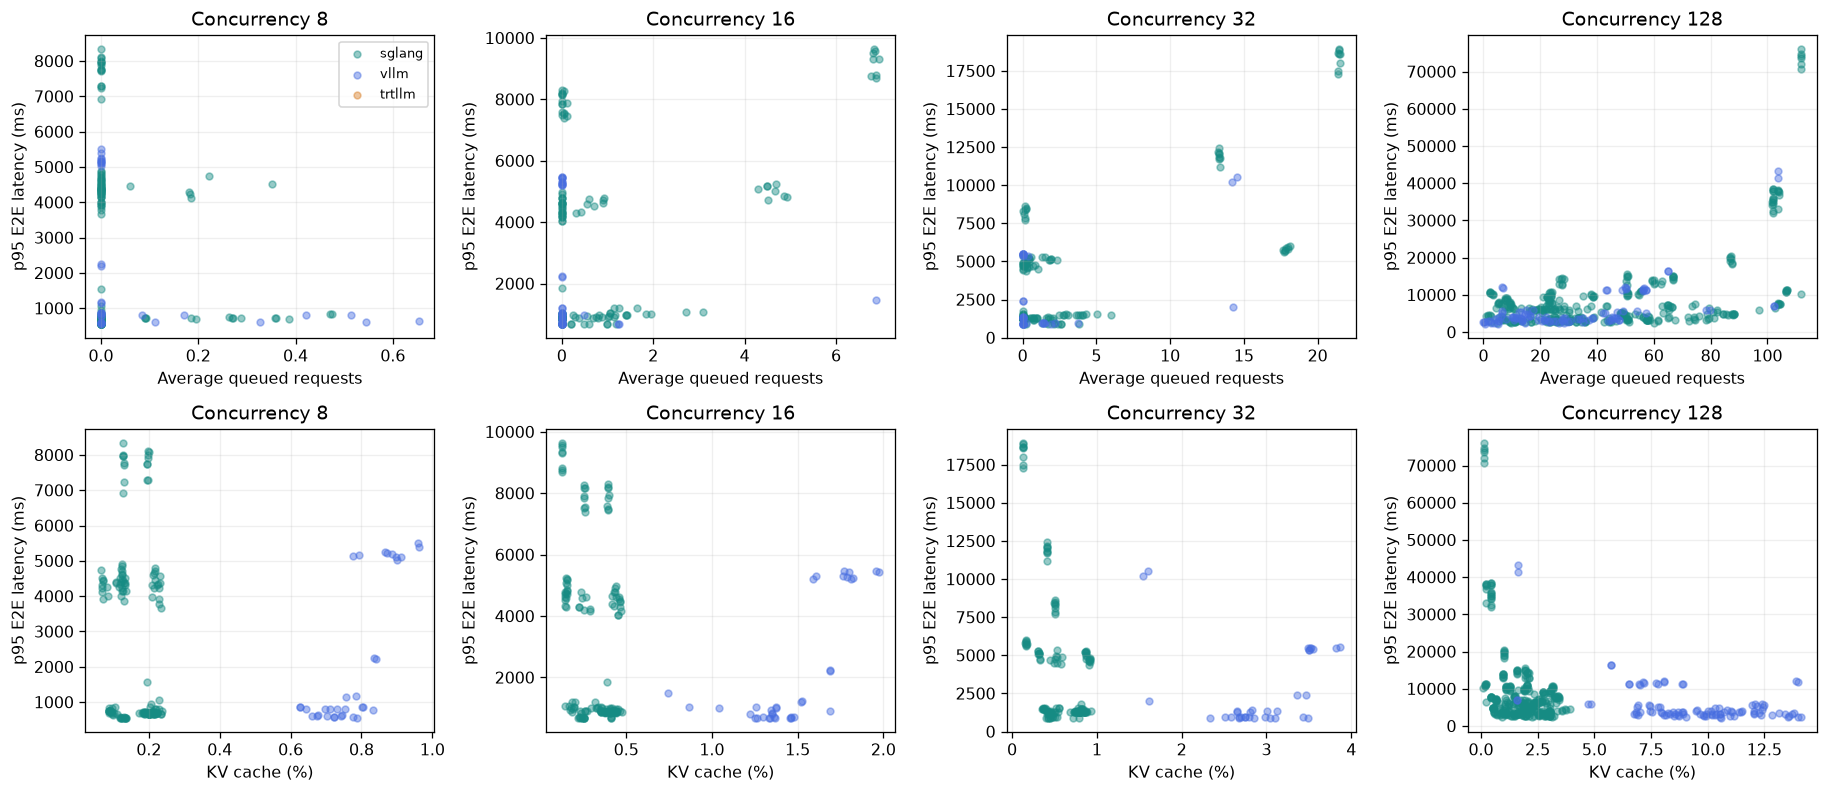

In [12]:
concurrencies = sorted(complete.concurrency.unique())
fig, axes = plt.subplots(2, len(concurrencies), figsize=(4 * len(concurrencies), 7), squeeze=False)
for i, metric in enumerate(["queued_requests", "kv_cache_utilization"]):
    for j, concurrency in enumerate(concurrencies):
        ax = axes[i, j]
        data = usable[(usable.metric == metric) & (usable.concurrency == concurrency)]
        for fw in FRAMEWORKS:
            frame = data[data.framework == fw]
            ax.scatter(frame.average * (100 if metric == "kv_cache_utilization" else 1), frame.p95_e2e_latency_ms,
                       color=COLORS[fw], label=fw, alpha=0.45, s=18)
        ax.set(title=f"Concurrency {concurrency}", xlabel="KV cache (%)" if metric == "kv_cache_utilization" else "Average queued requests", ylabel="p95 E2E latency (ms)")
        if i == 0 and j == 0: ax.legend(fontsize=8)
fig.tight_layout(); plt.show()

## Execution timings and failure coverage

Allocation wall time includes startup, preparation, warmup, benchmark, cleanup, rest, and
orchestration. It is an allocation-time proxy, not measured GPU busy time. The stacked plot uses
only the disjoint phase fields, excluding nested `runner_wall` and `allocation_wall` totals.
Log-derived compilation/capture observations may overlap, so they are not summed into phases.
Failure counts include all copied attempts; importance excludes failed and running trials.

,framework,concurrency,phase,mean_seconds,median_seconds,trials
0,sglang,8,allocation_wall,83.059140,79.795607,145
1,sglang,8,benchmark,14.093232,6.345966,145
2,sglang,8,cleanup,5.590934,5.666990,145
3,sglang,8,client_preparation,0.904601,0.894572,145
4,sglang,8,launch_to_ready,50.986362,46.019432,145
5,sglang,8,orchestration,1.078216,1.077734,145
6,sglang,8,rest,10.000110,10.000108,145
7,sglang,8,runner_wall,73.049575,69.786477,145
8,sglang,8,warmup,0.396229,0.161540,145
9,sglang,16,allocation_wall,84.527883,75.758226,154


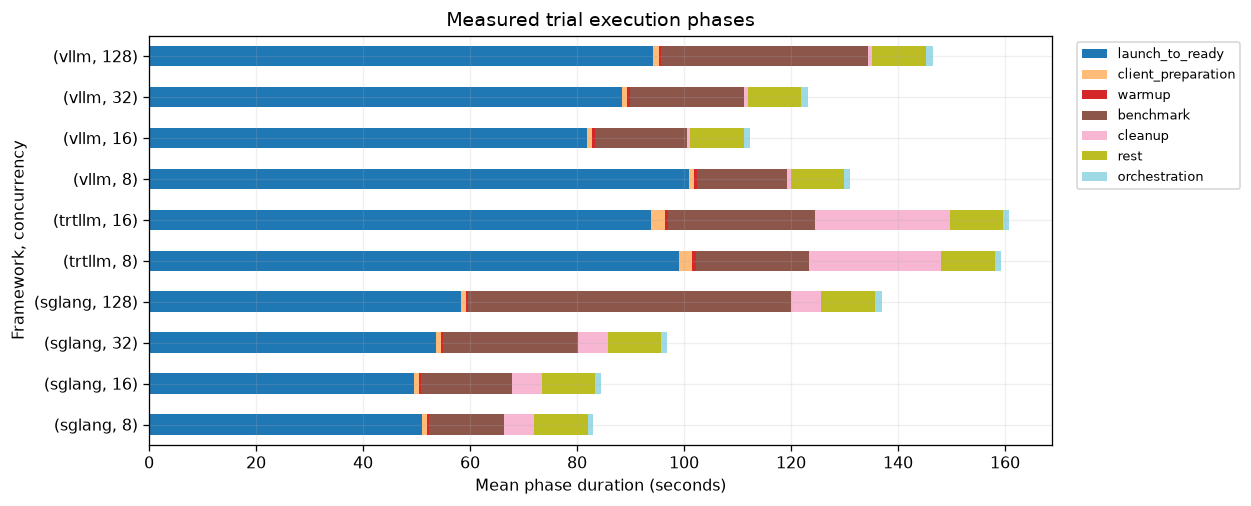

,,,attempts
framework,campaign,failure_reason,
trtllm,phase1-trtllm-v3-a6ceedccb3db5f00,ServerNotReadyError: Server did not become ready in the allotted time.,91


In [13]:
phase_order = ["launch_to_ready", "client_preparation", "warmup", "benchmark", "cleanup", "rest", "orchestration"]
timing_summary = timings.groupby(["framework", "concurrency", "phase"], as_index=False).agg(
    mean_seconds=("seconds", "mean"), median_seconds=("seconds", "median"), trials=("seconds", "size")
)
display(timing_summary)
matrix = timing_summary[timing_summary.phase.isin(phase_order)].pivot(index=["framework", "concurrency"], columns="phase", values="mean_seconds").reindex(columns=phase_order)
fig, ax = plt.subplots(figsize=(11, max(4, 0.45 * len(matrix))))
matrix.plot.barh(stacked=True, ax=ax, colormap="tab20")
ax.set(xlabel="Mean phase duration (seconds)", title="Measured trial execution phases", ylabel="Framework, concurrency")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
fig.tight_layout(); plt.show()
failures = trials[trials.state == "FAIL"]
if failures.empty:
    print("No failed attempts in the copied invest studies.")
else:
    display(failures.groupby(["framework", "campaign", "failure_reason"]).size().rename("attempts").to_frame())

## Snapshot findings and limits

The following findings are generated from this execution. Use the per-study plots and sample
counts before acting on a ranking. Missing optional parameters are not evidence of unimportance.
The final hash check verifies this notebook did not change any source database.

In [14]:
findings = []
for fw in FRAMEWORKS:
    frame = complete[complete.framework == fw]
    attempts = trials[trials.framework == fw]
    findings.append(f"**{fw}**: {len(frame)} completed measured trials from {frame.study_key.nunique()} studies; "
                    f"{attempts.state.eq('FAIL').sum()} failed, {attempts.state.eq('PRUNED').sum()} pruned, "
                    f"{attempts.state.eq('RUNNING').sum()} still marked running in the snapshot. "
                    f"Observed concurrency: {sorted(frame.concurrency.unique().tolist())}.")
for (fw, campaign, objective, concurrency, method), frame in summary.groupby(["framework", "campaign", "objective", "concurrency", "method"]):
    top = frame.sort_values("mean_importance", ascending=False).iloc[0]
    findings.append(f"{fw}, {campaign.rsplit('-', 1)[-1]}, {objective}, c={concurrency}, {method}: "
                    f"top parameter `{top.parameter}` ({top.mean_importance:.1%} mean importance; {top.n_studies} studies).")
gpu = telemetry[telemetry.metric == "gpu_utilization"]
findings.append(f"GPU utilization is available for {int(gpu.available.sum())}/{len(gpu)} completed measured trials; "
                "unavailable values are not plotted as zero.")
findings.append("Engine rankings are not controlled comparisons: objectives, sampled configurations, observed concurrency, "
                "and TensorRT-LLM's ModelOpt quantization artifact differ. Revalidate promising configurations with repeated measurements.")
display(Markdown("\n\n".join("- " + finding for finding in findings)))
for row in manifest.itertuples():
    assert sha256(ROOT / row.database) == row.sha256, f"Source changed during analysis: {row.database}"
assert complete.source.str.startswith("MEASURED").all()
assert complete.state.eq("COMPLETE").all()
assert not complete.duplicated(["study_key", "trial"]).any()
sums = importance.groupby(["study_key", "method"]).importance.sum()
assert np.allclose(sums, 1), "Importance normalization failed"
assert telemetry.loc[~telemetry.available, "average"].isna().all()
print("Verified: source hashes unchanged; measured COMPLETE trials only; unique trial keys; normalized importances; missing telemetry remains NaN.")

- **sglang**: 823 completed measured trials from 44 studies; 0 failed, 41 pruned, 1 still marked running in the snapshot. Observed concurrency: [8, 16, 32, 128].

- **vllm**: 204 completed measured trials from 12 studies; 0 failed, 36 pruned, 0 still marked running in the snapshot. Observed concurrency: [8, 16, 32, 128].

- **trtllm**: 108 completed measured trials from 10 studies; 91 failed, 0 pruned, 1 still marked running in the snapshot. Observed concurrency: [8, 16].

- sglang, 10195ab6a3fd087d, throughput, c=8, PED-ANOVA: top parameter `schedule_conservativeness` (23.3% mean importance; 2 studies).

- sglang, 10195ab6a3fd087d, throughput, c=8, fANOVA: top parameter `cuda_graph_backend_decode` (64.5% mean importance; 2 studies).

- sglang, 10195ab6a3fd087d, throughput, c=16, PED-ANOVA: top parameter `schedule_conservativeness` (19.6% mean importance; 2 studies).

- sglang, 10195ab6a3fd087d, throughput, c=16, fANOVA: top parameter `cuda_graph_backend_decode` (55.4% mean importance; 2 studies).

- sglang, 10195ab6a3fd087d, throughput, c=32, PED-ANOVA: top parameter `schedule_conservativeness` (36.5% mean importance; 2 studies).

- sglang, 10195ab6a3fd087d, throughput, c=32, fANOVA: top parameter `cuda_graph_backend_decode` (59.6% mean importance; 2 studies).

- sglang, 10195ab6a3fd087d, throughput, c=128, PED-ANOVA: top parameter `max_running_requests` (28.0% mean importance; 6 studies).

- sglang, 10195ab6a3fd087d, throughput, c=128, fANOVA: top parameter `cuda_graph_backend_decode` (47.4% mean importance; 6 studies).

- sglang, 564c6da21c60b22c, e2e, c=8, PED-ANOVA: top parameter `schedule_conservativeness` (28.8% mean importance; 2 studies).

- sglang, 564c6da21c60b22c, e2e, c=8, fANOVA: top parameter `cuda_graph_backend_decode` (21.8% mean importance; 2 studies).

- sglang, 564c6da21c60b22c, e2e, c=16, PED-ANOVA: top parameter `schedule_conservativeness` (27.9% mean importance; 2 studies).

- sglang, 564c6da21c60b22c, e2e, c=16, fANOVA: top parameter `cuda_graph_backend_decode` (15.8% mean importance; 2 studies).

- sglang, 564c6da21c60b22c, e2e, c=32, PED-ANOVA: top parameter `schedule_conservativeness` (19.9% mean importance; 2 studies).

- sglang, 564c6da21c60b22c, e2e, c=32, fANOVA: top parameter `max_running_requests` (26.1% mean importance; 2 studies).

- sglang, 564c6da21c60b22c, e2e, c=128, PED-ANOVA: top parameter `chunked_prefill_size` (15.0% mean importance; 6 studies).

- sglang, 564c6da21c60b22c, e2e, c=128, fANOVA: top parameter `max_running_requests` (36.8% mean importance; 6 studies).

- sglang, 5f5b4273b4cbdfa2, e2e, c=8, PED-ANOVA: top parameter `max_running_requests` (29.3% mean importance; 1 studies).

- sglang, 5f5b4273b4cbdfa2, e2e, c=8, fANOVA: top parameter `linear_attn_decode_backend` (27.9% mean importance; 1 studies).

- sglang, 5f5b4273b4cbdfa2, e2e, c=16, PED-ANOVA: top parameter `max_running_requests` (42.4% mean importance; 1 studies).

- sglang, 5f5b4273b4cbdfa2, e2e, c=16, fANOVA: top parameter `max_running_requests` (34.3% mean importance; 1 studies).

- sglang, 5f5b4273b4cbdfa2, e2e, c=32, PED-ANOVA: top parameter `max_running_requests` (57.6% mean importance; 1 studies).

- sglang, 5f5b4273b4cbdfa2, e2e, c=32, fANOVA: top parameter `max_running_requests` (34.6% mean importance; 1 studies).

- sglang, 5f5b4273b4cbdfa2, e2e, c=128, PED-ANOVA: top parameter `max_running_requests` (24.3% mean importance; 3 studies).

- sglang, 5f5b4273b4cbdfa2, e2e, c=128, fANOVA: top parameter `max_running_requests` (28.7% mean importance; 3 studies).

- sglang, 5f5b4273b4cbdfa2, throughput, c=8, PED-ANOVA: top parameter `max_running_requests` (38.3% mean importance; 1 studies).

- sglang, 5f5b4273b4cbdfa2, throughput, c=8, fANOVA: top parameter `cuda_graph_backend_decode` (53.8% mean importance; 1 studies).

- sglang, 5f5b4273b4cbdfa2, throughput, c=16, PED-ANOVA: top parameter `max_running_requests` (55.3% mean importance; 1 studies).

- sglang, 5f5b4273b4cbdfa2, throughput, c=16, fANOVA: top parameter `cuda_graph_backend_decode` (52.6% mean importance; 1 studies).

- sglang, 5f5b4273b4cbdfa2, throughput, c=32, PED-ANOVA: top parameter `max_running_requests` (55.1% mean importance; 1 studies).

- sglang, 5f5b4273b4cbdfa2, throughput, c=32, fANOVA: top parameter `cuda_graph_backend_decode` (59.0% mean importance; 1 studies).

- sglang, 5f5b4273b4cbdfa2, throughput, c=128, PED-ANOVA: top parameter `max_running_requests` (30.2% mean importance; 3 studies).

- sglang, 5f5b4273b4cbdfa2, throughput, c=128, fANOVA: top parameter `cuda_graph_backend_decode` (43.2% mean importance; 3 studies).

- sglang, ba0ce7f8e61093ca, throughput, c=8, PED-ANOVA: top parameter `schedule_conservativeness` (33.0% mean importance; 2 studies).

- sglang, ba0ce7f8e61093ca, throughput, c=8, fANOVA: top parameter `cuda_graph_backend_decode` (64.0% mean importance; 2 studies).

- sglang, ba0ce7f8e61093ca, throughput, c=16, PED-ANOVA: top parameter `schedule_conservativeness` (20.5% mean importance; 2 studies).

- sglang, ba0ce7f8e61093ca, throughput, c=16, fANOVA: top parameter `cuda_graph_backend_decode` (51.0% mean importance; 2 studies).

- sglang, ba0ce7f8e61093ca, throughput, c=32, PED-ANOVA: top parameter `schedule_conservativeness` (32.5% mean importance; 2 studies).

- sglang, ba0ce7f8e61093ca, throughput, c=32, fANOVA: top parameter `cuda_graph_backend_decode` (58.7% mean importance; 2 studies).

- sglang, ba0ce7f8e61093ca, throughput, c=128, PED-ANOVA: top parameter `schedule_conservativeness` (20.5% mean importance; 1 studies).

- sglang, ba0ce7f8e61093ca, throughput, c=128, fANOVA: top parameter `cuda_graph_backend_decode` (63.3% mean importance; 1 studies).

- trtllm, a6ceedccb3db5f00, throughput, c=8, PED-ANOVA: top parameter `max_num_tokens` (16.3% mean importance; 6 studies).

- trtllm, a6ceedccb3db5f00, throughput, c=8, fANOVA: top parameter `graph_enabled` (58.8% mean importance; 6 studies).

- trtllm, a6ceedccb3db5f00, throughput, c=16, PED-ANOVA: top parameter `max_batch_size` (21.8% mean importance; 4 studies).

- trtllm, a6ceedccb3db5f00, throughput, c=16, fANOVA: top parameter `graph_enabled` (69.0% mean importance; 4 studies).

- vllm, 0ccdf535d50afbb5, throughput, c=8, PED-ANOVA: top parameter `gpu_memory_utilization` (29.1% mean importance; 2 studies).

- vllm, 0ccdf535d50afbb5, throughput, c=8, fANOVA: top parameter `graph_mode` (81.0% mean importance; 2 studies).

- vllm, 0ccdf535d50afbb5, throughput, c=16, PED-ANOVA: top parameter `gpu_memory_utilization` (32.5% mean importance; 2 studies).

- vllm, 0ccdf535d50afbb5, throughput, c=16, fANOVA: top parameter `graph_mode` (71.2% mean importance; 2 studies).

- vllm, 0ccdf535d50afbb5, throughput, c=32, PED-ANOVA: top parameter `max_num_seqs` (27.5% mean importance; 2 studies).

- vllm, 0ccdf535d50afbb5, throughput, c=32, fANOVA: top parameter `graph_mode` (55.5% mean importance; 2 studies).

- vllm, 0ccdf535d50afbb5, throughput, c=128, PED-ANOVA: top parameter `max_num_seqs` (27.8% mean importance; 6 studies).

- vllm, 0ccdf535d50afbb5, throughput, c=128, fANOVA: top parameter `max_num_seqs` (30.0% mean importance; 6 studies).

- GPU utilization is available for 0/1135 completed measured trials; unavailable values are not plotted as zero.

- Engine rankings are not controlled comparisons: objectives, sampled configurations, observed concurrency, and TensorRT-LLM's ModelOpt quantization artifact differ. Revalidate promising configurations with repeated measurements.

Verified: source hashes unchanged; measured COMPLETE trials only; unique trial keys; normalized importances; missing telemetry remains NaN.
